# 06 The event field: per-pixel step maps, the mean event and its cross-fault shape

```
Created on Mon Sep 21 2026
@author: daniellelindsay
Run in opera_disp_feb13. The per-pixel fits take ~3 min per track; the rest is seconds.
```

**What this notebook does.** Notebook 04 measured the events on cross-fault
differences (east minus west medians). Here we map them: every pixel in a box
around Tule Pond gets its own time-function fit, so we see the SHAPE of each
event across the fault, not just its size. This is the observation half of
Fig 2; notebook 07 will invert the mean event for slip at depth.

1. **Per-pixel model** on each track: MintPy's `timeseries2velocity` model
   (intercept + linear rate + annual cycle + one Heaviside step per event, step
   dates from `creep_events.csv`), solved per pixel with NaN-aware least
   squares because `timeseries2velocity.py` refuses records with gaps.
2. **One data correction**, an explicit literal below: the descending
   burst-boundary offsets (measured per event and removed). The old chain also
   left the 2023 event out of the mean; here every event is kept (Dani,
   2026-09-21: five events unless it is much noisier, and it is not), and the
   2023 anomaly (its ascending step is cancelled by an east-block signal) is
   reported by the symmetric / antisymmetric split, not acted on.
3. **Mean event** = mean of the five step maps per track; written in the
   layout notebook 07 (CSI) reads.
4. **Decomposition** of the inter-event rate and the mean event into
   fault-parallel and vertical with MintPy's `asc_desc2horz_vert`, exactly as
   notebook 02 did for the whole fault, here with the local strike of the box.
5. **Profiles** X-X' (the Tule Pond peak) and Y-Y' (CFW1) across the
   fault-parallel maps (the numbers the text quotes) and across each track's
   LOS maps (what Fig 2 shows): the pixels, a one-pixel running median, and
   the model-free near-fault step (east band minus west band, the aperture
   of notebook 04). No fit here: the model is notebook 07.
6. Fig 2 (observations): the LOS maps and profiles of both tracks, the
   inter-event rate above the mean event, with the model row left to
   notebook 07; the fault-parallel maps and profiles go to the supplement.

Ported from `Hayward_DISP-S1/modelling/m01_step_maps.py` (steps 1 to 4),
`hayward_creep/analysis/event_map_profiles.py` (decomposition, profiles) and
`hayward_creep/plotting/plot_tulepond_secular_profiles.py` (fits, Fig 2).

**Inputs**: `timeseries_tropo.h5`, `maskTempCoh_07.h5`, `geometryGeo.h5` per
track; `04_event_detection/creep_events.csv` and `section_lengths.csv`;
`hayward_fault_profiles.csv`.

**Outputs** (`outputs/06_event_field_geometry/`): `tulepond_steps_<track>.h5`
(every per-event LOS step map, raw and burst-fixed, mean, scatter, rate,
geometry), `csi_mean_event_<track>.npz` (07's input), `fp_maps.npz`
(fault-parallel and vertical rate and mean event), `profile_<XX|YY>_<field>[_<track>].csv`,
`symmetry_table.csv`, `06_event_field_stats.txt`, registry rows `06_*`.

**Figures**: Fig 2 observations (pygmt; LOS per track), the fault-parallel
maps and profiles (supplement), the step-map grid (supplement), the
symmetry check (supplement).

**What to check.** Near-fault LOS steps of opposite sign on the two tracks
(ascending negative, descending positive, ratio near the geometric -0.6);
burst offsets under 1 mm; 2023 with a same-sign east-block patch on both
tracks; the mean event's fault-parallel profile an arctangent that decays
within a few hundred metres at X-X' and nothing at Y-Y'; the vertical
component near zero.

**Apertures.** Every near-fault step here is median(east band) minus
median(west band) with the SAME band as notebook 04 (`dist_min` to
`dist_max`, 30 to 150 m), so the two notebooks measure the same thing. A wider
band (100 to 500 m) makes the 2023 ascending step vanish because that event
carries a broad extra signal on the ascending west block within ~1 km; the
step at the trace is normal.

In [1]:
import os
import warnings

import insar_utils as utils
from TulePond_filepaths import (common_paths, insar_dic_list, creepmeters, box_lonlat,
                                coh_timeseries, az_smooth_n, dist_min, dist_max, paths_out, repo_dir, data_dir,
                                fig2_map_centre_km, fig2_map_half_km, fig2_map_extra_km)

import numpy as np
import pandas as pd
import pyproj
import h5py
import xarray as xr
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
utils.mpl_paper_style(base=8)          # Helvetica, 8 pt, editable PDF text
import pygmt
from mintpy.utils import time_func                                    # the design matrix timeseries2velocity uses
from mintpy.asc_desc2horz_vert import asc_desc2horz_vert              # THE decomposition, MintPy's own

## Constants

In [2]:
notebook = "06_event_field_geometry"
out_dir = paths_out[notebook]
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

unit = 1000                     # 1000 = mm
periodic = [1.0]                # annual cycle in the per-pixel model (years)
min_obs = 60                    # a pixel needs this many finite epochs to be fitted
geom_step = 20                  # MintPy's decomposition window (pixels), as notebook 02

# Descending burst boundaries in the box (found on the per-date increment maps,
# 2026-08-19; RESULTS.md section 2): lat = b + s * (lon + 122), s = -0.14 deg/deg,
# perpendicular to the descending track as burst boundaries are. The offset
# across each is measured per event in +/- burst_band_deg bands (excluding
# +/- burst_far_m around the trace) and removed as a step, holding the north
# side (which contains the reference pixel ZOA1) fixed. Ascending has none.
burst_lines = {"descending": [(-0.14, 37.536), (-0.14, 37.502)]}
burst_band_deg = 0.0015
burst_far_m = 400.0

# Events left out of the mean (onset years, matched to 0.02 yr). The old chain
# excluded 2023.08 (RESULTS.md section 2); with the five-event mean no noisier
# than four (scatter 0.89 vs 0.95 mm about the running median at X-X'), all five
# are kept. Set [2023.08] to reproduce the old product; the checks adapt.
exclude_events = []

# profiles across the fault-parallel maps, perpendicular to the local strike
profile_pts = {"X": (-121.97816, 37.56270),      # X-X': the trace point 58.5 km from Point Pinole (Dani, 2026-09-23, from a 200 m sweep of the event profiles: clean in both tracks, inside the 90% band)
               "Y": (-121.95233, 37.53214)}      # Y-Y': CFW1
cross_m = 2000.0                # +/- profile length (2 km: beyond that the east block is noisy)
swath_m = 150.0                 # +/- along-strike half-width
median_bin_m = 150.0            # running-median bin (five pixels), taken on each side of the fault separately
coh_maps = 0.9                  # temporal-coherence mask for the per-pixel maps and the decomposed field the slip model inverts
                                # (Dani 2026-09-28: the 0.7 maps are too noisy); the crossings and the LOS checks stay at coh_timeseries
far_m = (1500.0, 2000.0)        # same-block far field the near-fault amplitude of each block is measured against
median_col, grey, ann_col = "#A50F15", "gray55", "black"       # per-side running median (dark red); pixels; block annotation
rng_blk = np.random.default_rng(20260923)
event_far_m = 1500.0            # the event profile is zeroed on |x| >= this (far field, both blocks)
xfault_step_m = (dist_min * 1e3, dist_max * 1e3)   # the near-fault step band, the aperture of notebook 04 (m)

# symmetry check: cross-fault LOS profiles of every event, in the along-strike
# band of the stacked crossings (section_lengths.csv, the band Fig 1 uses), 100 m bins
sym_xmax_m, sym_bin_m, sym_eval_km = 3000.0, 100.0, 1.0

# Fig 2 map window (unrotated, north up): centred on the trace at map_centre_km from Point Pinole,
# +/- map_half_km east-west, +/- (map_half_km + map_extra_km) north-south, as the draft (10.4 x 12 km).
# The values live in TulePond_filepaths so Fig 1 (notebook 04) draws the same box.
map_centre_km, map_half_km, map_extra_km = fig2_map_centre_km, fig2_map_half_km, fig2_map_extra_km
aa_labelled = ["HGIL", "HRKT"]  # the arrays named in the paper (notebook 08); the other arrays of the section are not drawn
aa_label_pos = {"HGIL": ("RM", "-0.15c/0c"), "HRKT": ("LM", "0.15c/0.12c")}   # (justify, offset) of each label about its symbol

# legacy products for the gated parity checks (the old chain, coherence 0.9)
legacy_steps = {o: os.path.join(data_dir, "outputs", "modelling", o, "parkmont_steps_ex2023.h5" if exclude_events else "parkmont_steps.h5") for o in ("ascending", "descending")}
legacy_rate = os.path.join(data_dir, "outputs", "event_maps", "south_maps_look1.npz")

aa_file = common_paths["aa_summary"]
events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")
lengths_file = os.path.join(paths_out["04_event_detection"], "section_lengths.csv")

# saved-products mode (2026-09-28): on a machine without the MintPy stacks,
# the per-track products this notebook wrote (`tulepond_steps_<track>.h5`:
# every step map, the rate, the geometry, the mask) and `burst_offsets.csv`
# stand in for the MintPy files; the time-function fit and the burst fix
# are not redone. The decomposition CHECK below proves the path reproduces
# the MintPy-mode `fp_maps.npz` exactly.
saved_steps = {o: os.path.join(out_dir, f"tulepond_steps_{o}.h5") for o in ("ascending", "descending")}
from_saved_steps = not all(os.path.exists(dic["ts_file"]) for dic in insar_dic_list)
if from_saved_steps:
    assert all(os.path.exists(f) for f in saved_steps.values()), "no MintPy stacks and no saved step products"
    print("saved-products mode: reading tulepond_steps_<track>.h5 (MintPy stacks not on this machine)")

REG = utils.Registry(notebook, common_paths, repo_dir)
if from_saved_steps:
    REG.inputs(events_file, lengths_file, common_paths["fault_profiles"], aa_file,
               *saved_steps.values(), os.path.join(out_dir, "burst_offsets.csv"))
else:
    REG.inputs(events_file, lengths_file, common_paths["fault_profiles"], aa_file,
               *[dic[k] for dic in insar_dic_list for k in ("ts_file", "geo_file")],
               *[dic["mask_file"][coh_timeseries] for dic in insar_dic_list])

Registry for 06_event_field_geometry: run 26ab76f0, git f291100+


## LOAD: the events, the trace and the box

The box is `box_lonlat` (W, S, E, N) converted to a row/column slice of the
product grid. Both tracks are on the SAME grid (asserted), so one slice
serves both and the two LOS maps line up pixel for pixel.

In [3]:
ev = pd.read_csv(events_file)
tp = ev[ev.segment == "TULEPOND"].sort_values("onset_yr").reset_index(drop=True)
onsets = tp.onset_yr.to_numpy(float)
print(f"{len(tp)} Tule Pond events: {onsets}")

prof = pd.read_csv(common_paths["fault_profiles"])
prof["az_smooth"] = prof["profile_az"].rolling(az_smooth_n, center=True, min_periods=3).median()
lengths = pd.read_csv(lengths_file).set_index("name")
band = lengths.loc["tulepond_band90"]          # the band Fig 1 stacks (Dani, 2026-09-21: the 90% band)
in_box = (prof.ft_lat >= box_lonlat[1]) & (prof.ft_lat <= box_lonlat[3])
strike_box = float(np.nanmean(prof.loc[in_box, "az_smooth"] + 90.0))  # mean strike of the whole map box (used until 2026-09-28)
# the decomposition strike is the mean local strike of the SSE section (the
# creep-event section from 04, Dani 2026-09-28): the fault-parallel direction
# of the slipping patch, not of the whole 20 km map box
section = lengths.loc["tulepond_creep_length"]
in_section = (prof.ft_lat >= section.lat_lo) & (prof.ft_lat <= section.lat_hi)
strike = float(np.nanmean(prof.loc[in_section, "az_smooth"] + 90.0))
print(f"strike: SSE section (km {section.km_lo:.1f}-{section.km_hi:.1f}, {in_section.sum()} crossings) {strike:.2f} deg; "
      f"whole box {strike_box:.2f} deg (whole-fault mean in notebook 02: ~144)")
assert 130 < strike < 160

grid_files = list(saved_steps.values()) if from_saved_steps else [dic["ts_file"] for dic in insar_dic_list]
attrs = utils.load_h5_attrs(grid_files[0])     # saved products carry the box grid: offsets 0, full width
for f_grid_ in grid_files[1:]:
    a2 = utils.load_h5_attrs(f_grid_)
    for k in ("X_FIRST", "Y_FIRST", "X_STEP", "Y_STEP", "EPSG", "WIDTH", "LENGTH"):
        assert attrs[k] == a2[k], f"tracks are on different grids ({k}): {attrs[k]} vs {a2[k]}"
epsg = int(attrs["EPSG"])
to_utm = pyproj.Transformer.from_crs(4326, epsg, always_xy=True)
to_ll = pyproj.Transformer.from_crs(epsg, 4326, always_xy=True)

W_, S_, E_, N_ = box_lonlat
xs_, ys_ = to_utm.transform([W_, W_, E_, E_], [S_, N_, S_, N_])
x0, dx, y0, dy = (float(attrs[k]) for k in ("X_FIRST", "X_STEP", "Y_FIRST", "Y_STEP"))
c0, c1 = max(int(np.floor((min(xs_) - x0) / dx)), 0), min(int(np.ceil((max(xs_) - x0) / dx)), int(attrs["WIDTH"]))
r0, r1 = max(int(np.floor((max(ys_) - y0) / dy)), 0), min(int(np.ceil((min(ys_) - y0) / dy)), int(attrs["LENGTH"]))
nr, nc = r1 - r0, c1 - c0
print(f"box rows {r0}:{r1} cols {c0}:{c1} = {nr} x {nc} pixels of {abs(dx):.0f} m")

# pixel-centre coordinates of the box
Xg, Yg = np.meshgrid(x0 + (np.arange(c0, c1) + 0.5) * dx, y0 + (np.arange(r0, r1) + 0.5) * dy)
lon_g, lat_g = to_ll.transform(Xg, Yg)
# trace in UTM and the signed cross-fault distance of every pixel (+ = east / north-east side)
fx, fy = to_utm.transform(prof.ft_lon.values, prof.ft_lat.values)
tree = cKDTree(np.c_[fx, fy])
d_trace, j_near = tree.query(np.c_[Xg.ravel(), Yg.ravel()])
nrm = np.array([np.sin(np.deg2rad(strike - 90)), np.cos(np.deg2rad(strike - 90))])   # unit normal: strike - 90 is the NE side (+ east); strike + 90 would be SW
d_signed = ((np.c_[Xg.ravel(), Yg.ravel()] - np.c_[fx, fy][j_near]) @ nrm).reshape(nr, nc)
d_trace = d_trace.reshape(nr, nc)

5 Tule Pond events: [2017.0986 2019.1863 2021.1068 2023.0795 2024.9836]
strike: SSE section (km 56.3-62.3, 61 crossings) 146.44 deg; whole box 143.05 deg (whole-fault mean in notebook 02: ~144)
box rows 1647:2359 cols 1170:1944 = 712 x 774 pixels of 30 m


## RUN: the per-pixel time-function model on each track

MintPy's Heaviside is $H(t > t_{step})$, so the step date is set one day
BEFORE the acquisition nearest the onset: that acquisition is the first
post-event sample, as in notebook 04. The design matrix comes from
`mintpy.utils.time_func` (so it IS `timeseries2velocity`'s model); we only
replace its batch solver with a per-pixel one that skips missing epochs.
Pixels with complete records are solved in one matrix operation; the rest
one by one.

In [4]:
def step_dates_for(dates_yyyymmdd, onsets_yr):
    """(step_date, onset_epoch, onset_yr) per event: the acquisition nearest the onset, step the day before."""
    dts = pd.to_datetime(dates_yyyymmdd, format="%Y%m%d")
    yrs = np.array([utils.date_to_decimal_year(d) for d in dates_yyyymmdd])
    out = []
    for oy in onsets_yr:
        i = int(np.argmin(np.abs(yrs - oy)))
        out.append(((dts[i] - pd.Timedelta(days=1)).strftime("%Y%m%d"), dts[i].strftime("%Y%m%d"), float(oy)))
    return out


def fit_time_func(cube, dates, keep, step_dates):
    """Per-pixel least squares of MintPy's model (polynomial 1 + periodic + steps).
    cube (nt, nr, nc) in mm with NaN gaps; keep (nr, nc) bool. Returns dict of
    coefficient maps (mm, mm/yr), their formal errors and the residual RMS."""
    model = dict(polynomial=1, periodic=periodic, stepDate=list(step_dates), polyline=[], exp={}, log={})
    G = time_func.get_design_matrix4time_func(dates, model).astype(float)
    names = ["intercept", "velocity"] + [f"period{p}{c}" for p in periodic for c in ("Cos", "Sin")] + [f"step{d}" for d in step_dates]
    assert G.shape[1] == len(names)
    nt, nr_, nc_ = cube.shape
    Y = cube.reshape(nt, -1)
    npar = G.shape[1]
    m = np.full((npar, nr_ * nc_), np.nan, np.float32)
    ms = np.full((npar, nr_ * nc_), np.nan, np.float32)
    rms = np.full(nr_ * nc_, np.nan, np.float32)
    idx = np.nonzero(keep.reshape(-1))[0]
    fin = np.isfinite(Y[:, idx])
    full = fin.all(0)
    print(f"  fitting {len(idx)} pixels x {nt} dates, {npar} parameters: {full.sum()} complete records, {(~full).sum()} with gaps")
    if full.any():                                              # complete records: one solve
        c = np.linalg.lstsq(G, Y[:, idx[full]], rcond=None)[0]
        r = Y[:, idx[full]] - G @ c
        s2 = (r ** 2).sum(0) / (nt - npar)
        cov = np.linalg.inv(G.T @ G)
        m[:, idx[full]] = c
        ms[:, idx[full]] = np.sqrt(np.outer(np.diag(cov), s2))
        rms[idx[full]] = np.sqrt((r ** 2).mean(0))
    for j in idx[~full]:                                        # records with gaps: one at a time
        y = Y[:, j]; f = np.isfinite(y)
        if f.sum() < min_obs:
            continue
        Gj = G[f]
        c = np.linalg.lstsq(Gj, y[f], rcond=None)[0]
        r = y[f] - Gj @ c
        s2 = (r ** 2).sum() / max(f.sum() - npar, 1)
        m[:, j] = c
        ms[:, j] = np.sqrt(np.diag(np.linalg.inv(Gj.T @ Gj)) * s2)
        rms[j] = np.sqrt((r ** 2).mean())
    out = {n: m[i].reshape(nr_, nc_) for i, n in enumerate(names)}
    out.update({n + "Std": ms[i].reshape(nr_, nc_) for i, n in enumerate(names)})
    out["residualRMS"] = rms.reshape(nr_, nc_)
    return out, G, names

In [5]:
fits = {}           # per track: the coefficient maps, the geometry, the step dates
for dic in insar_dic_list:
    orbit = dic["ORBIT_DIRECTION"]
    if from_saved_steps:
        with h5py.File(saved_steps[orbit], "r") as h:
            n_ev = len([k for k in h.keys() if k.startswith("event") and k[5:].isdigit()])
            steps = [(h[f"event{i}"].attrs["step_date"], h[f"event{i}"].attrs["onset_epoch"],
                      float(h[f"event{i}"].attrs["onset_yr"])) for i in range(n_ev)]
            fits[orbit] = dict(coef=None, keep=h["coh_mask"][:].astype(bool), inc=h["incidenceAngle"][:],
                               azi=h["azimuthAngle"][:], steps=steps, dates=None)
        print(f"  {orbit}: steps at {[s0 for s0, _, _ in steps]} (saved products)")
        continue
    f_fit = os.path.join(out_dir, f"timefunc_fit_{orbit}.npz")
    with h5py.File(dic["ts_file"], "r") as h:
        dates = [d.decode() for d in h["date"][:]]
    steps = step_dates_for(dates, onsets)
    with h5py.File(dic["mask_file"][coh_timeseries], "r") as h:
        keep = h[[k for k in h.keys() if k != "date"][0]][r0:r1, c0:c1].astype(bool)
    with h5py.File(dic["geo_file"], "r") as h:                  # loaded as notebook 02 does (float32, as MintPy wrote it)
        inc = h["incidenceAngle"][r0:r1, c0:c1].astype(np.float32)
        azi = h["azimuthAngle"][r0:r1, c0:c1].astype(np.float32)
    if os.path.exists(f_fit):                                   # gated: the fit is the slow step
        z = np.load(f_fit)
        assert list(z["step_dates"]) == [s0 for s0, _, _ in steps], "cached fit was made with other step dates; delete it"
        coef = {k: z[k] for k in z.files if k not in ("step_dates", "names")}
        print(f"[{orbit}] per-pixel fit loaded from {os.path.basename(f_fit)}")
    else:
        with h5py.File(dic["ts_file"], "r") as h:
            cube = h["timeseries"][:, r0:r1, c0:c1].astype(np.float32) * unit     # m -> mm
        cube[cube == 0] = np.nan                                # MintPy no-data
        print(f"[{orbit}] {len(dates)} dates, coherent pixels {keep.mean():.0%} of the box")
        coef, G, names = fit_time_func(cube, dates, keep, [s0 for s0, _, _ in steps])
        np.savez(f_fit, step_dates=np.array([s0 for s0, _, _ in steps]), names=np.array(names), **coef)
        del cube
    fits[orbit] = dict(coef=coef, keep=keep, inc=inc, azi=azi, steps=steps, dates=dates)
    print(f"  {orbit}: steps at {[s0 for s0, _, _ in steps]} (onset epochs {[o for _, o, _ in steps]})")

[ascending] per-pixel fit loaded from timefunc_fit_ascending.npz
  ascending: steps at ['20170205', '20190309', '20210208', '20230129', '20241225'] (onset epochs ['20170206', '20190310', '20210209', '20230130', '20241226'])
[descending] per-pixel fit loaded from timefunc_fit_descending.npz
  descending: steps at ['20170124', '20190303', '20210208', '20230129', '20241225'] (onset epochs ['20170125', '20190304', '20210209', '20230130', '20241226'])


## CHECK 1: MintPy's design matrix is the one we think it is

Build the same matrix by hand (1, t, cos 2πt, sin 2πt, H(t > t_step)) on
MintPy's own time axis and fit a synthetic series with a known 10 mm step
through both. The step estimates must agree to 1e-9 mm: the two matrices
span the same model. MintPy's decimal year (`ptime.yyyymmdd2years`) differs
from our exact-seconds one by up to a few hours; the effect on a step is
printed and is far below the noise.

In [6]:
from mintpy.utils import ptime

# saved-products mode: the MintPy date axis is not on this machine; the
# check tests MintPy's design-matrix construction (not our data) and passed
# when the products were written
if from_saved_steps:
    print("CHECK 1 skipped in saved-products mode (needs the MintPy date axis)")
else:

    dates = fits["descending"]["dates"]
    step_dates = [s0 for s0, _, _ in fits["descending"]["steps"]]
    model = dict(polynomial=1, periodic=periodic, stepDate=step_dates, polyline=[], exp={}, log={})
    G_mp = time_func.get_design_matrix4time_func(dates, model).astype(float)
    t = np.array(ptime.yyyymmdd2years(dates), float)
    t_step = np.array(ptime.yyyymmdd2years(step_dates), float)
    G_hand = np.column_stack([np.ones_like(t), t, np.cos(2 * np.pi * t), np.sin(2 * np.pi * t)] + [(t > ts).astype(float) for ts in t_step])
    rng = np.random.default_rng(0)
    y = 2.0 * (t - t[0]) + 1.5 * np.sin(2 * np.pi * t) + 10.0 * (t > t_step[1]) + rng.normal(0, 0.5, t.size)
    c_mp = np.linalg.lstsq(G_mp, y, rcond=None)[0]
    c_hand = np.linalg.lstsq(G_hand, y, rcond=None)[0]
    print("step coefficients, MintPy design:", c_mp[4:].round(6))
    print("step coefficients, hand design:  ", c_hand[4:].round(6))
    assert np.allclose(c_mp[4:], c_hand[4:], atol=1e-9) and abs(c_mp[1] - c_hand[1]) < 1e-9
    print("PASS: MintPy's time-function design is intercept + rate + annual + Heaviside(t > step date)")
    # the year convention: ours (exact seconds) against MintPy's
    t_ours = np.array([utils.date_to_decimal_year(d) for d in dates])
    G_ours = np.column_stack([np.ones_like(t), t_ours, np.cos(2 * np.pi * t_ours), np.sin(2 * np.pi * t_ours)] + [(t > ts).astype(float) for ts in t_step])
    c_ours = np.linalg.lstsq(G_ours, y, rcond=None)[0]
    print(f"note: MintPy's decimal years differ from ours by up to {24 * 365.25 * np.abs(t - t_ours).max():.1f} h; "
          f"the steps move by at most {np.abs(c_ours[4:] - c_mp[4:]).max():.3f} mm (the fit uses MintPy's)")

step coefficients, MintPy design: [-0.17539   9.971329 -0.05404  -0.09205   0.088333]
step coefficients, hand design:   [-0.17539   9.971329 -0.05404  -0.09205   0.088333]
PASS: MintPy's time-function design is intercept + rate + annual + Heaviside(t > step date)
note: MintPy's decimal years differ from ours by up to 17.9 h; the steps move by at most 0.008 mm (the fit uses MintPy's)


## RUN: read the step maps, mask, remove the box median, fix the descending bursts

The box median of each step map is removed (the InSAR datum is ZOA1, an
arbitrary constant here). The burst correction measures, per event, the
median offset between two thin bands either side of each burst line, away
from the fault, and shifts the south side onto the north side.

In [7]:
event_maps = {}
burst_log = []
for dic in insar_dic_list:
    orbit = dic["ORBIT_DIRECTION"]
    F = fits[orbit]
    if from_saved_steps:
        with h5py.File(saved_steps[orbit], "r") as h:
            n_ev = len(F["steps"])
            event_maps[orbit] = dict(ev=np.stack([h[f"event{i}"][:] for i in range(n_ev)]),
                                     ev_raw=np.stack([h[f"event{i}_raw"][:] for i in range(n_ev)]),
                                     ev_std=np.stack([h[f"event{i}Std"][:] for i in range(n_ev)]),
                                     rate=h["rate"][:])
        continue
    keys = [f"step{s0}" for s0, _, _ in F["steps"]]
    evm = np.stack([F["coef"][k] for k in keys]).astype(float)              # (n_ev, nr, nc), mm
    evs = np.stack([F["coef"][k + "Std"] for k in keys]).astype(float)
    rate = F["coef"]["velocity"].astype(float)                              # mm/yr
    evm[:, ~F["keep"]] = np.nan; rate[~F["keep"]] = np.nan
    evm -= np.nanmedian(evm, axis=(1, 2))[:, None, None]                    # box median per event
    evm_raw = evm.copy()
    if orbit in burst_lines:
        far = d_trace > burst_far_m
        for (sl, b) in burst_lines[orbit]:
            dl = lat_g - sl * (lon_g + 122.0)
            nb = (dl > b) & (dl < b + burst_band_deg) & far
            sb = (dl < b) & (dl > b - burst_band_deg) & far
            south = dl < b
            for i, (_, _, oy) in enumerate(F["steps"]):
                off = np.nanmedian(evm[i][nb]) - np.nanmedian(evm[i][sb])
                evm[i][south] += off
                burst_log.append(dict(track=orbit, line_lat=b, onset_yr=oy, offset_mm=off, n_north=int(nb.sum()), n_south=int(sb.sum())))
                print(f"  [{orbit}] event {oy:.2f}: offset across the lat {b:.3f} burst line {off:+.2f} mm removed")
    event_maps[orbit] = dict(ev=evm, ev_raw=evm_raw, ev_std=evs, rate=rate)
if from_saved_steps:
    burst_df = pd.read_csv(os.path.join(out_dir, "burst_offsets.csv"))
else:
    burst_df = pd.DataFrame(burst_log)
    burst_df.to_csv(os.path.join(out_dir, "burst_offsets.csv"), index=False)
assert (burst_df.offset_mm.abs() < 2.0).all(), "a burst offset above 2 mm is not the +/-1 mm scatter described; look at the maps"

  [descending] event 2017.10: offset across the lat 37.536 burst line -0.42 mm removed
  [descending] event 2019.19: offset across the lat 37.536 burst line -0.23 mm removed
  [descending] event 2021.11: offset across the lat 37.536 burst line -0.12 mm removed
  [descending] event 2023.08: offset across the lat 37.536 burst line -0.08 mm removed
  [descending] event 2024.98: offset across the lat 37.536 burst line -0.95 mm removed
  [descending] event 2017.10: offset across the lat 37.502 burst line +0.30 mm removed
  [descending] event 2019.19: offset across the lat 37.502 burst line +0.01 mm removed
  [descending] event 2021.11: offset across the lat 37.502 burst line +0.27 mm removed
  [descending] event 2023.08: offset across the lat 37.502 burst line +0.92 mm removed
  [descending] event 2024.98: offset across the lat 37.502 burst line +0.16 mm removed


## CHECK 2: the near-fault LOS step of every event, both tracks

Model-free: median of the east band minus median of the west band
(30 to 150 m from the trace, notebook 04's aperture) within the stacked section. Fault-parallel
creep projects with OPPOSITE signs into the two geometries (ascending looks
west, descending east), so the ascending step must be negative, the descending
positive, and their ratio near the geometric value from the two LOS vectors.

In [8]:
in_band = (lat_g >= band.lat_lo) & (lat_g <= band.lat_hi)
east = in_band & (d_signed > xfault_step_m[0]) & (d_signed < xfault_step_m[1])
west = in_band & (d_signed < -xfault_step_m[0]) & (d_signed > -xfault_step_m[1])
L = {o: utils.los_unit_vector(np.nanmedian(fits[o]["inc"][in_band]), np.nanmedian(fits[o]["azi"][in_band])) for o in event_maps}
s_hat = utils.horizontal_unit_vector(strike)
geom_ratio = float((L["ascending"] @ s_hat) / (L["descending"] @ s_hat))
print(f"LOS . strike: asc {L['ascending'] @ s_hat:+.3f}, desc {L['descending'] @ s_hat:+.3f}; geometric asc/desc ratio {geom_ratio:+.2f}")

step_rows = []
for i, (_, _, oy) in enumerate(fits["ascending"]["steps"]):
    row = dict(onset_yr=oy)
    for o in event_maps:
        m_ = event_maps[o]["ev"][i]
        row[f"{o}_step_mm"] = float(np.nanmedian(m_[east]) - np.nanmedian(m_[west]))
    row["ratio_asc_desc"] = row["ascending_step_mm"] / row["descending_step_mm"]
    step_rows.append(row)
steps_df = pd.DataFrame(step_rows)
print(steps_df.round(2).to_string(index=False))
kept = ~steps_df.onset_yr.apply(lambda oy: any(abs(oy - x) < 0.02 for x in exclude_events))
m_asc, m_desc = steps_df.ascending_step_mm[kept].mean(), steps_df.descending_step_mm[kept].mean()
print(f"mean of the {kept.sum()} kept events: asc {m_asc:+.2f} mm, desc {m_desc:+.2f} mm, ratio {m_asc / m_desc:+.2f} (geometric {geom_ratio:+.2f})")
assert m_asc < 0 < m_desc, "the mean event has the wrong LOS sign: the geometry or the fault side is wrong"
assert (steps_df.descending_step_mm > 0).all(), "a descending step with the wrong sign"
off = steps_df[steps_df.ascending_step_mm >= 0]
for _, r_ in off.iterrows():
    print(f"NOTE {r_.onset_yr:.2f}: ascending step {r_.ascending_step_mm:+.2f} mm, ratio {r_.ratio_asc_desc:+.2f}: its ascending step is cancelled by an east-block signal (see the symmetry check)")
print("PASS: the mean event steps negative on ascending and positive on descending; every descending step is positive")

LOS . strike: asc -0.263, desc +0.468; geometric asc/desc ratio -0.56
 onset_yr  ascending_step_mm  descending_step_mm  ratio_asc_desc
  2017.10              -2.48                4.10           -0.60
  2019.19              -1.43                5.21           -0.28
  2021.11              -2.61                4.13           -0.63
  2023.08              -1.23                5.73           -0.21
  2024.98              -1.16                3.52           -0.33
mean of the 5 kept events: asc -1.78 mm, desc +4.54 mm, ratio -0.39 (geometric -0.56)
PASS: the mean event steps negative on ascending and positive on descending; every descending step is positive


## CHECK 3: symmetric and antisymmetric parts of every event

A cross-fault LOS profile $p(x)$ of pure strike-slip is antisymmetric about
the trace: $p(-x) = -p(x)$. We split each event's profile (100 m bins, zeroed
at the trace) into $A = (p(x) - p(-x))/2$ (the slip) and
$S = (p(x) + p(-x))/2$ (whatever is the same on both blocks: vertical,
atmosphere), read at 1 km. 2023 should stand out with a large S of the SAME
sign on both tracks; that is the reason it is left out of the mean.

In [9]:
bins = np.arange(-sym_xmax_m, sym_xmax_m + sym_bin_m, sym_bin_m); bc = 0.5 * (bins[1:] + bins[:-1])
j_eval = int(np.argmin(np.abs(bc - sym_eval_km * 1e3)))
sym_rows, sym_prof = [], {}
for o in event_maps:
    base = in_band & (np.abs(d_signed) < sym_xmax_m)
    idx = np.digitize(d_signed[base], bins) - 1
    for i, (_, _, oy) in enumerate(fits[o]["steps"]):
        v = event_maps[o]["ev"][i][base]
        p = np.array([np.nanmedian(v[idx == j]) if (idx == j).sum() >= 15 else np.nan for j in range(bc.size)])
        p = p - np.nanmean(p[np.abs(bc) <= 150])                    # zero at the trace
        A, S = 0.5 * (p - p[::-1]), 0.5 * (p + p[::-1])
        sym_prof[(o, oy)] = (p, A, S)
        sym_rows.append(dict(track=o, onset_yr=oy, antisym_1km_mm=A[j_eval], sym_1km_mm=S[j_eval]))
sym_df = pd.DataFrame(sym_rows)
sym_wide = sym_df.pivot(index="onset_yr", columns="track", values=["antisym_1km_mm", "sym_1km_mm"])
print(sym_wide.round(2).to_string())
sym_df.to_csv(os.path.join(out_dir, "symmetry_table.csv"), index=False)

# The event that stands out: the largest ascending symmetric (non-slip) part and the asc/desc
# near-fault step ratio furthest from the geometric value (an east-block signal cancels its
# ascending step). Note the symmetric parts have OPPOSITE signs on the two tracks for every
# event at 1 km, i.e. the common-mode signal is mostly horizontal, not vertical. Reported
# always; asserted to be the excluded event only when one is excluded.
S_asc = sym_df[sym_df.track == "ascending"].set_index("onset_yr").sym_1km_mm
ratio_dev = (steps_df.set_index("onset_yr").ratio_asc_desc - geom_ratio).abs()
oy_sym, oy_ratio = float(S_asc.abs().idxmax()), float(ratio_dev.idxmax())
print(f"largest ascending symmetric part: {oy_sym:.2f} ({S_asc[oy_sym]:+.2f} mm; others at most {S_asc.drop(oy_sym).abs().max():.2f}); "
      f"most anomalous step ratio: {oy_ratio:.2f} ({steps_df.set_index('onset_yr').ratio_asc_desc[oy_ratio]:+.2f} against the geometric {geom_ratio:+.2f})")
for x in exclude_events:
    assert abs(oy_sym - x) < 0.02 and abs(oy_ratio - x) < 0.02, f"the excluded event {x} is not the anomalous one ({oy_sym:.2f}, {oy_ratio:.2f})"
print("PASS" if exclude_events else "no event excluded: the anomaly is reported, not acted on")

          antisym_1km_mm            sym_1km_mm           
track          ascending descending  ascending descending
onset_yr                                                 
2017.0986          -0.36       0.64      -0.17       0.51
2019.1863          -0.03       1.39      -1.22       0.54
2021.1068          -0.10       0.63      -0.34       0.97
2023.0795           0.50       0.57      -1.96       0.37
2024.9836           0.06       0.76      -0.67       0.53
largest ascending symmetric part: 2023.08 (-1.96 mm; others at most 1.22); most anomalous step ratio: 2023.08 (-0.21 against the geometric -0.56)
no event excluded: the anomaly is reported, not acted on


In [10]:
# QC figure: every event's LOS profile on both tracks; the descending scaled by the geometric ratio should sit on the ascending
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex=True, sharey=True)
for ax, (i, (_, _, oy)) in zip(axes.flat, enumerate(fits["ascending"]["steps"])):
    pa, _, _ = sym_prof[("ascending", oy)]; pd_, _, _ = sym_prof[("descending", oy)]
    ax.plot(bc / 1e3, pa, color="#0072B2", lw=1.5, label="ascending LOS")
    ax.plot(bc / 1e3, pd_ * geom_ratio, color="#E69F00", lw=1.5, label=f"descending LOS x {geom_ratio:+.2f}")
    ax.axvline(0, color="k", lw=0.6); ax.axhline(0, color="k", lw=0.4)
    ax.set_title(f"{oy:.2f}" + ("  (excluded)" if any(abs(oy - x) < 0.02 for x in exclude_events) else ""), fontsize=9)
axes[0, 0].legend(fontsize=7)
axes[-1, -1].axis("off")
for ax in axes[-1]: ax.set_xlabel("cross-fault distance (km, + east)")
for ax in axes[:, 0]: ax.set_ylabel("LOS step (mm, zero at the trace)")
fig.suptitle(f"Event LOS profiles in the stacked band ({band.lat_lo:.3f} to {band.lat_hi:.3f} N): pure strike-slip puts orange on blue", fontsize=9)
fig.tight_layout()
f_sym = os.path.join(fig_dir, "figS_event_symmetry.png")
fig.savefig(f_sym, dpi=300); print("Saved figure to:", f_sym); plt.show()

Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-28/figS_event_symmetry.png


/var/folders/bz/z50q20pn1fsbtbkbs0bcrqf00000gp/T/ipykernel_87038/1699398957.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig(f_sym, dpi=300); print("Saved figure to:", f_sym); plt.show()


## RUN: the mean event per track, written for the slip model

Mean of the kept events per pixel (only where all of them are valid), the
per-pixel scatter across events, and the formal error of the mean. Written
to `tulepond_steps_<track>.h5` (everything) and `csi_mean_event_<track>.npz`
(the flat table notebook 07 reads: lon, lat, LOS mm, error, incidence, azimuth).

In [11]:
mean_event = {}
for dic in insar_dic_list:
    orbit = dic["ORBIT_DIRECTION"]
    F, M = fits[orbit], event_maps[orbit]
    if from_saved_steps:
        with h5py.File(saved_steps[orbit], "r") as h:
            mean_event[orbit] = dict(mean=h["mean_event"][:], scatter=h["event_scatter"][:],
                                     err=h["mean_event_err"][:], n=int(h.attrs["n_events"]))
        print(f"[{orbit}] mean event read from {os.path.basename(saved_steps[orbit])} (not rewritten)")
        continue
    keep_ev = np.array([not any(abs(oy - x) < 0.02 for x in exclude_events) for _, _, oy in F["steps"]])
    ev, ev_std = M["ev"][keep_ev], M["ev_std"][keep_ev]
    n_ok = np.isfinite(ev).sum(0)
    mean = np.where(n_ok == keep_ev.sum(), np.nanmean(ev, 0), np.nan)
    scatter = np.where(n_ok == keep_ev.sum(), np.nanstd(ev, 0, ddof=1), np.nan)
    err_mean = np.sqrt(np.nanmean(ev_std ** 2, 0)) / np.sqrt(keep_ev.sum())
    good = np.isfinite(mean)
    mean_event[orbit] = dict(mean=mean, scatter=scatter, err=err_mean, n=int(keep_ev.sum()))
    f_h5 = os.path.join(out_dir, f"tulepond_steps_{orbit}.h5")
    with h5py.File(f_h5, "w") as h:
        for i, (sd, od, oy) in enumerate(F["steps"]):
            g = h.create_dataset(f"event{i}", data=M["ev"][i].astype(np.float32))
            g.attrs.update(dict(step_date=sd, onset_epoch=od, onset_yr=oy, in_mean=bool(keep_ev[i])))
            h.create_dataset(f"event{i}Std", data=M["ev_std"][i].astype(np.float32))
            h.create_dataset(f"event{i}_raw", data=M["ev_raw"][i].astype(np.float32))
        for k2, v in dict(mean_event=mean, event_scatter=scatter, mean_event_err=err_mean, rate=M["rate"],
                          incidenceAngle=F["inc"], azimuthAngle=F["azi"], lon=lon_g, lat=lat_g, coh_mask=F["keep"]).items():
            h.create_dataset(k2, data=np.asarray(v, dtype=np.float32))
        h.attrs.update({k: str(v) for k, v in attrs.items()})
        h.attrs.update(dict(X_FIRST=str(x0 + c0 * dx), Y_FIRST=str(y0 + r0 * dy), WIDTH=str(nc), LENGTH=str(nr), UNIT="mm",
                            n_events=int(keep_ev.sum()), excluded=str(exclude_events), coherence=str(coh_timeseries),
                            note="LOS + toward satellite; box median removed per event; azimuthAngle = LOS ground->sat, anticlockwise from N",
                            provenance=utils.provenance_stamp(notebook, repo_dir)))
    np.savez(os.path.join(out_dir, f"csi_mean_event_{orbit}.npz"), lon=lon_g[good], lat=lat_g[good], vel_mm=mean[good],
             err_mm=err_mean[good], incidence=F["inc"][good], azimuth=F["azi"][good], scatter_mm=scatter[good])
    print(f"[{orbit}] mean of {keep_ev.sum()} events: {good.sum()} pixels, 2-98% {np.nanpercentile(mean, 2):+.1f} to {np.nanpercentile(mean, 98):+.1f} mm, "
          f"median scatter {np.nanmedian(scatter):.2f} mm; wrote {os.path.basename(f_h5)} and csi_mean_event_{orbit}.npz")

[ascending] mean of 5 events: 256161 pixels, 2-98% -4.0 to +3.4 mm, median scatter 1.78 mm; wrote tulepond_steps_ascending.h5 and csi_mean_event_ascending.npz


/var/folders/bz/z50q20pn1fsbtbkbs0bcrqf00000gp/T/ipykernel_87038/2456804374.py:14: RuntimeWarning: Mean of empty slice
  mean = np.where(n_ok == keep_ev.sum(), np.nanmean(ev, 0), np.nan)
/Users/dlindsay/miniforge3/envs/opera_disp_feb13/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/var/folders/bz/z50q20pn1fsbtbkbs0bcrqf00000gp/T/ipykernel_87038/2456804374.py:16: RuntimeWarning: Mean of empty slice
  err_mean = np.sqrt(np.nanmean(ev_std ** 2, 0)) / np.sqrt(keep_ev.sum())
/var/folders/bz/z50q20pn1fsbtbkbs0bcrqf00000gp/T/ipykernel_87038/2456804374.py:14: RuntimeWarning: Mean of empty slice
  mean = np.where(n_ok == keep_ev.sum(), np.nanmean(ev, 0), np.nan)
/Users/dlindsay/miniforge3/envs/opera_disp_feb13/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dt

[descending] mean of 5 events: 234205 pixels, 2-98% -3.1 to +2.9 mm, median scatter 1.64 mm; wrote tulepond_steps_descending.h5 and csi_mean_event_descending.npz


## CHECK 4 (gated): parity with the legacy step maps

`outputs/modelling/<track>/parkmont_steps.h5` (m01, coherence 0.9) holds
the same fit on the same data; per-pixel fits do not depend on the mask, so on
the pixels both have, the mean events must agree to a constant (the box
median differs) apart from the burst offsets (measured on different pixel
sets). Robust scatter of the difference under 0.1 mm = the same product.

In [12]:
n_compared = 0
for orbit in mean_event:
    f_leg = legacy_steps[orbit]
    if not os.path.exists(f_leg):
        print(f"[{orbit}] no legacy file, parity check skipped"); continue
    n_compared += 1
    with h5py.File(f_leg, "r") as h:
        m_leg = h["mean_event"][:].astype(float)
        lx0, ly0 = float(h.attrs["X_FIRST"]), float(h.attrs["Y_FIRST"])
    assert abs(lx0 - (x0 + c0 * dx)) < 1 and abs(ly0 - (y0 + r0 * dy)) < 1 and m_leg.shape == (nr, nc), "legacy box differs; compare by coordinates"
    diff = mean_event[orbit]["mean"] - m_leg
    both = np.isfinite(diff)
    sig = utils.robust_sigma(diff[both])
    print(f"[{orbit}] {both.sum()} common pixels: median difference {np.nanmedian(diff[both]):+.3f} mm (datum), robust scatter {sig:.3f} mm")
    assert sig < 0.1, f"{orbit}: the new mean event differs from the legacy product by more than a constant"
if n_compared:
    print(f"PASS: mean events equal the legacy m01 products up to the datum ({n_compared} tracks compared)")
else:
    print("CHECK 4 not run: no legacy products on this machine")

[ascending] 165774 common pixels: median difference +0.100 mm (datum), robust scatter 0.000 mm
[descending] 167555 common pixels: median difference -0.021 mm (datum), robust scatter 0.000 mm
PASS: mean events equal the legacy m01 products up to the datum (2 tracks compared)


## RUN: fault-parallel and vertical maps

`asc_desc2horz_vert` (MintPy) on the inter-event rate and on the mean event,
with each track's own incidence and azimuth and `horz_az_angle = -strike`
(MintPy counts anticlockwise), as notebook 02. The vertical component of
creep is ~0, so the Up maps are the QC: they should be flat across the
trace.

In [13]:
def decompose(v_asc, v_des, strike_deg=None):
    strike_deg = strike if strike_deg is None else strike_deg
    both_ = np.isfinite(v_asc) & np.isfinite(v_des)
    dlos = np.stack([v_asc, v_des]).astype(np.float32); dlos[:, ~both_] = np.nan
    los_inc = np.stack([fits["ascending"]["inc"], fits["descending"]["inc"]]).astype(np.float32)
    los_azi = np.stack([fits["ascending"]["azi"], fits["descending"]["azi"]]).astype(np.float32)
    fp_, up_ = asc_desc2horz_vert(dlos, los_inc, los_azi, horz_az_angle=-strike_deg, step=geom_step)
    return fp_.astype(float), up_.astype(float)


# CHECK (2026-09-28): at the whole-box strike this path must reproduce the
# fp_maps.npz written in MintPy mode (kept as fp_maps_strike143_reference.npz)
# exactly; everything after it differs from that file by the strike alone
f_ref = os.path.join(out_dir, "fp_maps_strike143_reference.npz")
if os.path.exists(f_ref):
    ref = np.load(f_ref)
    assert abs(float(ref["strike"]) - strike_box) < 1e-9, "reference was made at another strike"
    chk_fp, chk_up = decompose(mean_event["ascending"]["mean"], mean_event["descending"]["mean"], strike_box)
    chk_fpr, chk_upr = decompose(event_maps["ascending"]["rate"], event_maps["descending"]["rate"], strike_box)
    for name_, new_, old_ in (("fp_event", chk_fp, ref["fp_event"]), ("up_event", chk_up, ref["up_event"]),
                              ("fp_rate", chk_fpr, ref["fp_rate"]), ("up_rate", chk_upr, ref["up_rate"])):
        same_nan = np.array_equal(np.isnan(new_), np.isnan(old_))
        diff = float(np.nanmax(np.abs(new_ - old_)))
        print(f"{name_} at the box strike ({strike_box:.2f} deg): NaN pattern identical {same_nan}, max |difference| {diff:.2e}")
        assert same_nan and diff == 0.0, f"{name_} differs from the MintPy-mode product"
    print("PASS: this path reproduces the MintPy-mode decomposition exactly; now the SSE-section strike")

# the per-pixel maps from here on (decomposition, profiles, Fig 2) use the
# stricter coh_maps mask; it lies inside the coh_timeseries mask the step
# maps were fitted on, so it only removes pixels
if coh_maps != coh_timeseries:
    for dic in insar_dic_list:
        orbit = dic["ORBIT_DIRECTION"]
        with h5py.File(dic["mask_file"][coh_maps], "r") as h:
            mx0, my0 = float(h.attrs["X_FIRST"]), float(h.attrs["Y_FIRST"])
            col0 = int(round((x0 + c0 * dx - mx0) / dx)); row0 = int(round((y0 + r0 * dy - my0) / dy))
            mask_maps = h[[k for k in h.keys() if k != "date"][0]][row0:row0 + nr, col0:col0 + nc].astype(bool)
        assert not (mask_maps & ~fits[orbit]["keep"]).any(), f"{orbit}: coh_maps mask not inside the fit mask"
        for key_ in ("mean", "scatter", "err"):
            mean_event[orbit][key_] = np.where(mask_maps, mean_event[orbit][key_], np.nan)
        event_maps[orbit]["rate"] = np.where(mask_maps, event_maps[orbit]["rate"], np.nan)
        event_maps[orbit]["ev"] = np.where(mask_maps[None], event_maps[orbit]["ev"], np.nan)
        print(f"[{orbit}] maps masked at temporal coherence {coh_maps}: {mask_maps.mean():.0%} of the box "
              f"(fit mask {coh_timeseries}: {fits[orbit]['keep'].mean():.0%})")

fp_rate, up_rate = decompose(event_maps["ascending"]["rate"], event_maps["descending"]["rate"])
fp_evt, up_evt = decompose(mean_event["ascending"]["mean"], mean_event["descending"]["mean"])
fp_events = {}
for i, (_, _, oy) in enumerate(fits["ascending"]["steps"]):
    fp_events[oy], _ = decompose(event_maps["ascending"]["ev"][i], event_maps["descending"]["ev"][i])

def block_step(m_):
    return float(np.nanmedian(m_[east]) - np.nanmedian(m_[west]))

print(f"inter-event FP rate step east - west (100-500 m, stacked band): {block_step(fp_rate):+.2f} mm/yr; Up {block_step(up_rate):+.2f} mm/yr")
print(f"mean event FP step: {block_step(fp_evt):+.2f} mm; Up {block_step(up_evt):+.2f} mm (should be ~0: creep has no vertical part)")
for oy, m_ in fp_events.items():
    print(f"  event {oy:.2f}: FP step {block_step(m_):+.2f} mm")
np.savez(os.path.join(out_dir, "fp_maps.npz"), fp_rate=fp_rate, up_rate=up_rate, fp_event=fp_evt, up_event=up_evt,
         lon=lon_g, lat=lat_g, X=Xg, Y=Yg, strike=strike, n_events=mean_event["ascending"]["n"],
         **{f"fp_event_{oy:.2f}": m_ for oy, m_ in fp_events.items()})

[ascending] maps masked at temporal coherence 0.9: 30% of the box (fit mask 0.7: 46%)
[descending] maps masked at temporal coherence 0.9: 30% of the box (fit mask 0.7: 42%)


decomposing asc/desc into horz/vert direction in windows of 20x20 ...
[=>                       3%                       ] 1/36    0s /     0s

[==>                      6%                       ] 2/36    0s /     0s

[===>                     8%                       ] 3/36    0s /     0s

[=====>                  11%                       ] 4/36    0s /     0s

[======>                 14%                       ] 5/36    0s /     0s

... (251 outputs left out)

[======================= 94% ==================>   ] 34/36    0s /     0s

[======================= 97% ===================>  ] 35/36    0s /     0s

[==================================================] 36/36

 
inter-event FP rate step east - west (100-500 m, stacked band): +1.37 mm/yr; Up -0.88 mm/yr
mean event FP step: +8.83 mm; Up +0.52 mm (should be ~0: creep has no vertical part)
  event 2017.10: FP step +9.01 mm
  event 2019.19: FP step +8.85 mm
  event 2021.11: FP step +9.50 mm
  event 2023.08: FP step +9.64 mm
  event 2024.98: FP step +6.62 mm


## CHECK 5 (gated): the inter-event rate map against the legacy one

`outputs/event_maps/south_maps_look1.npz` (event_map_profiles.py) solved the
rate with ramps for the events instead of steps, coherence 0.9, and a
west-block reference, then decomposed the same way. Same field, different
solver: correlation above 0.95 on the common pixels.

In [14]:
f_leg = legacy_rate
if os.path.exists(f_leg):
    z = np.load(f_leg)
    lx0, ly0, lxs, lys = (float(z[k]) for k in ("geo_X_FIRST", "geo_Y_FIRST", "geo_X_STEP", "geo_Y_STEP"))
    m_leg = z["map_rate"]
    # sample the legacy grid at our pixel centres (both 30 m; offsets are whole pixels)
    ci = np.round((Xg - lx0) / lxs - 0.5).astype(int); ri = np.round((Yg - ly0) / lys - 0.5).astype(int)
    okp = (ci >= 0) & (ci < m_leg.shape[1]) & (ri >= 0) & (ri < m_leg.shape[0])
    leg = np.full(fp_rate.shape, np.nan); leg[okp] = m_leg[ri[okp], ci[okp]]
    both = np.isfinite(leg) & np.isfinite(fp_rate)
    corr = float(np.corrcoef(leg[both], fp_rate[both])[0, 1])
    print(f"inter-event FP rate vs legacy: {both.sum()} common pixels, correlation {corr:.3f}, "
          f"block step {block_step(fp_rate):+.2f} vs {block_step(leg):+.2f} mm/yr")
    assert corr > 0.95
    print("PASS")
else:
    print("no legacy rate map, check skipped")

inter-event FP rate vs legacy: 142221 common pixels, correlation 0.997, block step +1.37 vs +0.74 mm/yr
PASS


## RUN: the cross-fault profiles X-X' and Y-Y'

Perpendicular to the LOCAL strike at each point (the smoothed strike of the
mapped trace there, not the box mean), +/- `cross_m`, all pixels within
+/- `swath_m` along strike, plus a per-side running median.
The inter-event profile is zeroed at the fault (mid-point of the two block
medians within 1 km); the event profile on its far field. The same machinery
runs on the fault-parallel maps (the numbers the text quotes) and on each
track's LOS maps (what Fig 2 shows).

In [15]:
def local_strike(lonlat):
    """Smoothed local strike of the mapped trace (compass bearing) at the trace point nearest lonlat."""
    cx, cy = (float(t_) for t_ in to_utm.transform(*lonlat))
    j = int(tree.query([cx, cy])[1])
    return float(prof.az_smooth.iloc[j] + 90.0)


def profile(m_, lonlat, strike_deg=None):
    """Cross-fault profile of map m_ through lonlat, perpendicular to the LOCAL strike
    there (or to strike_deg): d (m, + east), v, the line's end points (UTM), the strike used."""
    cx, cy = (float(t_) for t_ in to_utm.transform(*lonlat))
    if strike_deg is None:
        strike_deg = local_strike(lonlat)
    pe, pn = np.sin(np.deg2rad(strike_deg - 90.0)), np.cos(np.deg2rad(strike_deg - 90.0))   # cross-fault unit vector (+ east)
    se, sn = -pn, pe                                            # along-strike
    dc = (Xg - cx) * pe + (Yg - cy) * pn; da = (Xg - cx) * se + (Yg - cy) * sn
    sel = (np.abs(da) <= swath_m) & (np.abs(dc) <= cross_m) & np.isfinite(m_)
    d, v = dc[sel], m_[sel]
    o = np.argsort(d)
    ends = (cx - cross_m * pe, cy - cross_m * pn, cx + cross_m * pe, cy + cross_m * pn)
    return d[o], v[o], ends, strike_deg


def running_median(d, v, bin_m=median_bin_m):
    """Binned median on each side of the fault separately: the bin edges start at
    the trace and run outward, so no bin (and no drawn segment) straddles the
    fault. Returns a list of (x, median) arrays, one per side (west, east)."""
    out = []
    for sgn in (-1, 1):
        edges = np.sort(sgn * np.arange(0.0, cross_m + bin_m, bin_m))
        idx = np.digitize(d, edges)
        xc, med = [], []
        for i in range(1, len(edges)):
            m_ = (idx == i) & (sgn * d > 0)
            if m_.sum() >= 3:
                xc.append(0.5 * (edges[i - 1] + edges[i])); med.append(np.median(v[m_]))
        out.append((np.array(xc), np.array(med)))
    return out


def block_amplitudes(d, v, n_boot=2000):
    """Per-block near-fault amplitude of a profile: median of the near band
    (`xfault_step_m`, 30 to 150 m) minus the median of the SAME block's far field
    (`far_m`), with a bootstrap standard error over the pixels. Reads the peak
    value of each block off the profile without any model."""
    out = {}
    for blk, sgn in (("W", -1), ("E", 1)):
        near = (sgn * d >= xfault_step_m[0]) & (sgn * d < xfault_step_m[1])
        far = (sgn * d >= far_m[0]) & (sgn * d < far_m[1])
        assert near.sum() >= 10 and far.sum() >= 50, (blk, near.sum(), far.sum())
        vn, vf = v[near], v[far]
        boot = np.array([np.median(rng_blk.choice(vn, vn.size)) - np.median(rng_blk.choice(vf, vf.size)) for _ in range(n_boot)])
        out[blk] = dict(amp=float(np.median(vn) - np.median(vf)), se=float(boot.std()), far=float(np.median(vf)),
                        n_near=int(near.sum()), n_far=int(far.sum()))
    return out


def zeroed_profiles(m_rate, m_evt, lonlat):
    """The rate and event profiles through lonlat, zeroed (rate: mid-point of the
    block medians within 1 km; event: its far field), and their near-fault steps
    (east minus west medians, the 30 to 150 m aperture of notebook 04)."""
    d, v, ends, st = profile(m_rate, lonlat)
    near = np.abs(d) <= 1000
    v = v - 0.5 * (np.median(v[near & (d < 0)]) + np.median(v[near & (d > 0)]))
    de, ve, _, _ = profile(m_evt, lonlat, st)
    far = np.abs(de) >= event_far_m
    ve = ve - (np.median(ve[far]) if far.sum() >= 20 else np.median(ve))
    lo_, hi_ = xfault_step_m
    r_step = float(np.median(v[(d > lo_) & (d < hi_)]) - np.median(v[(d < -lo_) & (d > -hi_)]))
    e_step = float(np.median(ve[(de > lo_) & (de < hi_)]) - np.median(ve[(de < -lo_) & (de > -hi_)]))
    return dict(d=d, v=v, de=de, ve=ve, ends=ends, lonlat=lonlat, strike=st, rate_step=r_step, event_step=e_step)


# fault-parallel: the numbers the text quotes
profiles = {}
for name, lonlat in profile_pts.items():
    p = zeroed_profiles(fp_rate, fp_evt, lonlat)
    profiles[name] = p
    pd.DataFrame(dict(d_m=p["d"], fp_rate_mm_yr=p["v"])).to_csv(os.path.join(out_dir, f"profile_{name}{name}_rate.csv"), index=False)
    pd.DataFrame(dict(d_m=p["de"], fp_event_mm=p["ve"])).to_csv(os.path.join(out_dir, f"profile_{name}{name}_event.csv"), index=False)
    print(f"{name}-{name}' FP (local strike {p['strike']:.1f} deg): {p['d'].size} rate pixels, {p['de'].size} event pixels; near-fault steps ({xfault_step_m[0]:.0f}-{xfault_step_m[1]:.0f} m): "
          f"rate {p['rate_step']:+.2f} mm/yr, event {p['event_step']:+.2f} mm")
print("legacy (coherence 0.9, 2026-08-30, 1-D fits): X-X' event 9.12 mm, Y-Y' 2.68 mm")

# line of sight, per track: what Fig 2 shows (LOS positive toward the satellite, so
# right-lateral slip steps NEGATIVE on ascending and POSITIVE on descending)
tracks = ["ascending", "descending"]
los_profiles = {o: {n_: zeroed_profiles(event_maps[o]["rate"], mean_event[o]["mean"], ll) for n_, ll in profile_pts.items()} for o in tracks}
for o in tracks:
    for n_, p in los_profiles[o].items():
        pd.DataFrame(dict(d_m=p["d"], los_rate_mm_yr=p["v"])).to_csv(os.path.join(out_dir, f"profile_{n_}{n_}_rate_{o}.csv"), index=False)
        pd.DataFrame(dict(d_m=p["de"], los_event_mm=p["ve"])).to_csv(os.path.join(out_dir, f"profile_{n_}{n_}_event_{o}.csv"), index=False)
        p["blocks"] = block_amplitudes(p["de"], p["ve"])
        blk = p["blocks"]
        print(f"[{o[:3]}] {n_}-{n_}' LOS: rate step {p['rate_step']:+.2f} mm/yr, event step {p['event_step']:+.2f} mm; "
              f"event per block W {blk['W']['amp']:+.2f} +/- {blk['W']['se']:.2f}, E {blk['E']['amp']:+.2f} +/- {blk['E']['se']:.2f} mm")
xx_ratio = los_profiles["ascending"]["X"]["event_step"] / los_profiles["descending"]["X"]["event_step"]
print(f"X-X' event asc/desc LOS step ratio {xx_ratio:+.2f} (geometric, pure strike-slip: {geom_ratio:+.2f})")
assert los_profiles["ascending"]["X"]["event_step"] < 0 < los_profiles["descending"]["X"]["event_step"], "the X-X' LOS event steps have the wrong signs"

X-X' FP (local strike 149.1 deg): 1190 rate pixels, 1190 event pixels; near-fault steps (30-150 m): rate +1.17 mm/yr, event +9.28 mm


Y-Y' FP (local strike 142.5 deg): 1177 rate pixels, 1177 event pixels; near-fault steps (30-150 m): rate +6.61 mm/yr, event +0.76 mm
legacy (coherence 0.9, 2026-08-30, 1-D fits): X-X' event 9.12 mm, Y-Y' 2.68 mm


[asc] X-X' LOS: rate step -0.90 mm/yr, event step -2.37 mm; event per block W +1.87 +/- 0.11, E -0.41 +/- 0.08 mm


[asc] Y-Y' LOS: rate step -2.23 mm/yr, event step +0.39 mm; event per block W -0.14 +/- 0.09, E -0.20 +/- 0.22 mm


[des] X-X' LOS: rate step -0.05 mm/yr, event step +4.55 mm; event per block W -2.61 +/- 0.15, E +1.26 +/- 0.09 mm


[des] Y-Y' LOS: rate step +2.83 mm/yr, event step +1.11 mm; event per block W -0.63 +/- 0.16, E +0.57 +/- 0.10 mm
X-X' event asc/desc LOS step ratio -0.52 (geometric, pure strike-slip: -0.56)


## CHECK 6: what the ascending deficit needs

Pure strike-slip puts the ascending near-fault step at `geom_ratio` times the
descending one; the mean event's ratio is smaller in magnitude (the ascending
step is short). Two LOS observations cannot separate three components, so
we solve the two end members exactly: strike-slip plus VERTICAL (east side up
positive) and strike-slip plus FAULT-NORMAL (east block moving away from the
fault, i.e. opening, positive). Either a few mm of east-side-up or of
east-side contraction closes the gap; the two-block forward model in the
supplement (TwoBlock_LOS_test) shows the same thing panel by panel. This is
the reason notebook 07 inverts the descending track alone.

In [16]:
u_hat = np.array([0.0, 0.0, 1.0])
n_hat = utils.horizontal_unit_vector(strike - 90.0)          # fault-normal, toward the east (NE) block
d_obs = np.array([m_asc, m_desc])                              # mean near-fault LOS steps (CHECK 2), mm
asym = {}
for comp, c_hat in (("up", u_hat), ("normal", n_hat)):
    G2 = np.array([[L[o] @ s_hat, L[o] @ c_hat] for o in tracks])
    fp_c, x_c = np.linalg.solve(G2, d_obs)
    asym[comp] = (float(fp_c), float(x_c))
fp_only = float(np.linalg.lstsq(np.array([[L[o] @ s_hat] for o in tracks]), d_obs, rcond=None)[0][0])
print(f"mean near-fault LOS steps: asc {m_asc:+.2f}, desc {m_desc:+.2f} mm (ratio {m_asc / m_desc:+.2f}, geometric {geom_ratio:+.2f})")
print(f"strike-slip only (least squares on both tracks): {fp_only:.2f} mm")
print(f"strike-slip + vertical:     FP {asym['up'][0]:.2f} mm, east side up {asym['up'][1]:+.2f} mm")
print(f"strike-slip + fault-normal: FP {asym['normal'][0]:.2f} mm, east block opening {asym['normal'][1]:+.2f} mm (negative = contraction)")
print(f"LOS sensitivities: up asc {L['ascending'] @ u_hat:+.3f} desc {L['descending'] @ u_hat:+.3f}; "
      f"normal asc {L['ascending'] @ n_hat:+.3f} desc {L['descending'] @ n_hat:+.3f}")

mean near-fault LOS steps: asc -1.78, desc +4.54 mm (ratio -0.39, geometric -0.56)
strike-slip only (least squares on both tracks): 8.99 mm
strike-slip + vertical:     FP 8.67 mm, east side up +0.66 mm
strike-slip + fault-normal: FP 12.25 mm, east block opening -2.40 mm (negative = contraction)
LOS sensitivities: up asc +0.756 desc +0.729; normal asc -0.600 desc +0.500


## Fig 2: the observations on each track, and the model row (notebook 07)

Layout (Dani's sketch, 2026-09-23). Row 1, the inter-event rate: the
ascending and descending LOS maps sharing one colour bar, then the X-X' and
Y-Y' profiles of each track (pixels in grey, a per-side running median in
blue). Row 2, the mean event: the same, with each block's near-fault amplitude
over its own far field (text at the panel bottom). Row 3 is the
model, descending only, which notebook 07 will draw (the quadtree samples,
the model, the residual, and slip with depth); until then it is three
labelled empty frames of the sizes 07 will fill, so the page can be judged.
The maps are LOS, positive toward the satellite, so the same right-lateral
step is blue-over-red on ascending and red-over-blue on descending. The
fault-parallel maps and profiles this figure used to show are now a
supplementary figure (next section).

map window: 10.4 x 12 km about 59.5 km (37.5547 N)


alignment arrays in the window: HAPP, HCAM, HGIL, HHAN, HONO, HPIN, HPMD, HRKT, HSGR, HUNI
map panels 3.59 x 4.05 cm; figure ~18.1 x 15.5 cm
common pixel mask for the four maps: 149165 pixels (27% of the box)


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


Saved to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-28/fig2_observations_los_coh0.9_5ev.png


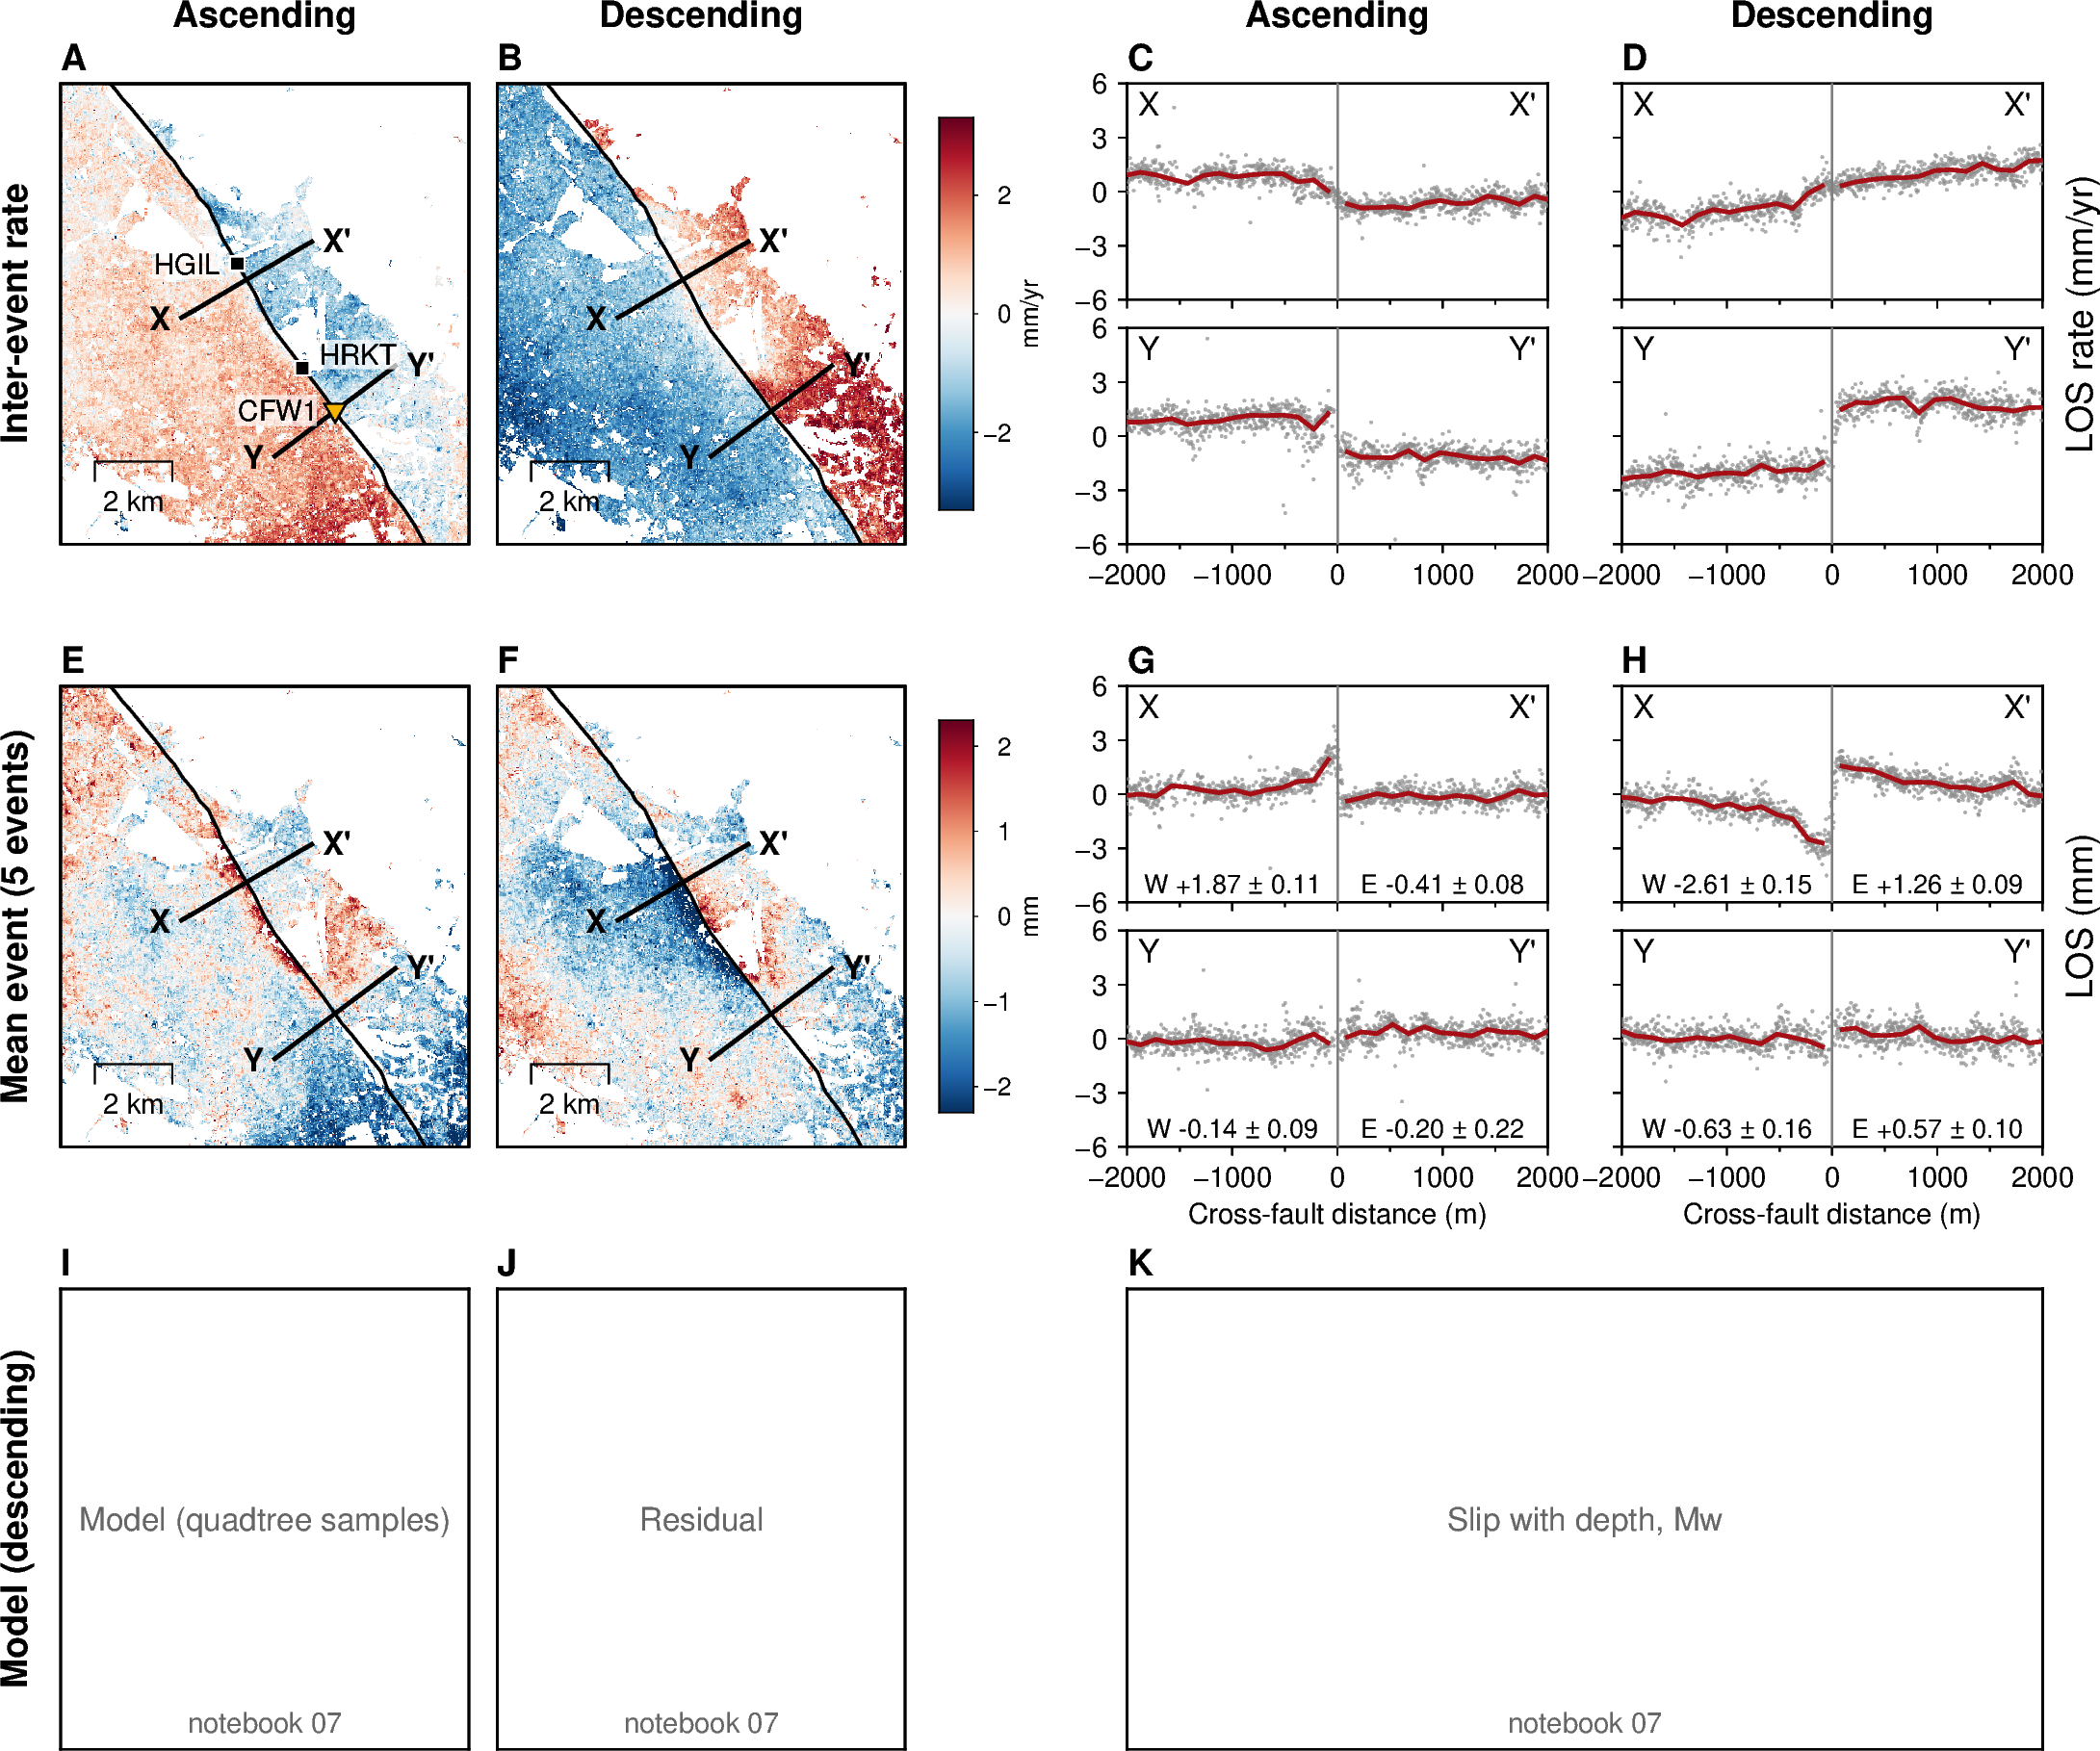

In [17]:
# --- the map window: a lon/lat box about the trace point map_centre_km from Point Pinole
km_of = utils.lat_to_km_map(common_paths["fault_profiles"])
j_c = int(np.argmin(np.abs(km_of(prof.ft_lat.values) - map_centre_km)))
xc, yc = (float(t_) for t_ in to_utm.transform(prof.ft_lon[j_c], prof.ft_lat[j_c]))
lon_w, lat_s = to_ll.transform(xc - map_half_km * 1e3, yc - (map_half_km + map_extra_km) * 1e3)
lon_e, lat_n = to_ll.transform(xc + map_half_km * 1e3, yc + (map_half_km + map_extra_km) * 1e3)
region_map = [lon_w, lon_e, lat_s, lat_n]
print(f"map window: {2 * map_half_km:g} x {2 * (map_half_km + map_extra_km):g} km about {map_centre_km:g} km ({prof.ft_lat[j_c]:.4f} N)")

# the maps on a regular lon/lat grid (nearest 30 m pixel)
lat_q = np.arange(lat_s - 0.002, lat_n + 0.002, 0.00025)
lon_q = np.arange(lon_w - 0.002, lon_e + 0.002, 0.0003)
LONq, LATq = np.meshgrid(lon_q, lat_q)
Eq, Nq = to_utm.transform(LONq, LATq)
ci = np.round((Eq - (x0 + c0 * dx)) / dx - 0.5).astype(int); ri = np.round((Nq - (y0 + r0 * dy)) / dy - 0.5).astype(int)
okq = (ci >= 0) & (ci < nc) & (ri >= 0) & (ri < nr)
_, jq = tree.query(np.c_[Eq.ravel(), Nq.ravel()])
side_q = ((np.c_[Eq.ravel(), Nq.ravel()] - np.c_[fx, fy][jq]) @ nrm).reshape(Eq.shape)    # + east of the trace


def to_grid(m_, balance):
    z = np.full(LONq.shape, np.nan); z[okq] = m_[ri[okq], ci[okq]]
    if balance:                                                 # fault at zero: mid-point of the two block medians in the window
        z -= 0.5 * (np.nanmedian(z[side_q < 0]) + np.nanmedian(z[side_q > 0]))
    lim = max(float(np.nanpercentile(np.abs(z[np.isfinite(z)]), 98)), 0.3)
    return xr.DataArray(z, coords={"lat": lat_q, "lon": lon_q}, dims=("lat", "lon")), lim


def gmt_map_size(region, projection):
    """Width and height (cm) GMT gives a region/projection pair (mapproject -W)."""
    with pygmt.clib.Session() as lib:
        f_ = os.path.join(out_dir, "cpt", "dims.txt")
        lib.call_module("mapproject", f"-R{'/'.join(str(r) for r in region)} -J{projection} -W ->{f_}")
    return tuple(float(x) for x in open(f_).read().split())


cpt_dir = os.path.join(out_dir, "cpt"); os.makedirs(cpt_dir, exist_ok=True)
lines_ll = {n_: to_ll.transform(np.array([p["ends"][0], p["ends"][2]]), np.array([p["ends"][1], p["ends"][3]])) for n_, p in profiles.items()}
cfw = [c for c in creepmeters if c[0] == "CFW1"][0]
aa = utils.load_aa_summary(aa_file)
aa = aa[(aa.long_deg > lon_w) & (aa.long_deg < lon_e) & (aa.lat_deg > lat_s) & (aa.lat_deg < lat_n)]
print("alignment arrays in the window:", ", ".join(aa.site_code))

# --- sizes (cm): a double-column figure (18 cm)
Wp, Hp = 3.7, 1.9                                   # one profile panel
gap_pair, gap_col, gap_row = 0.25, 0.65, 1.25       # within a stacked pair; between the two profile columns (room for the +/-2000 labels); between rows
Hpair = 2 * Hp + gap_pair                           # a stacked pair; the maps are made exactly this tall
w_, h_ = gmt_map_size(region_map, "M4c")
Wm, Hm = 4.0 * Hpair / h_, Hpair
proj_map = f"M{Wm:.3f}c"
gap_map, cb_w, gap_cb = 0.25, 0.3, 0.3              # between the two maps; colour-bar width; map-to-bar gap
x_prof = 2 * Wm + gap_map + gap_cb + cb_w + 1.35    # left edge of the profile columns (room for the bar label and the y annotation)
W_model = 2 * Wp + gap_col                          # the slip-model panel spans both profile columns
print(f"map panels {Wm:.2f} x {Hm:.2f} cm; figure ~{x_prof + W_model + 0.7:.1f} x {3 * Hpair + 2 * gap_row + 0.9:.1f} cm")
names = list(profile_pts)
lim_prof = {"rate": 6.0, "event": 6.0}              # LOS profile axes (mm/yr, mm); the FP figure uses 10
n_mean = mean_event["ascending"]["n"]
pygmt.config(FONT="8p,Helvetica", FONT_ANNOT_PRIMARY="7p,Helvetica", FONT_LABEL="7p,Helvetica", MAP_FRAME_TYPE="plain",
             MAP_FRAME_PEN="0.6p", MAP_TICK_LENGTH_PRIMARY="2p", MAP_LABEL_OFFSET="4p", MAP_ANNOT_OFFSET="3p", FORMAT_GEO_MAP="ddd.xx")
fig = None                      # the helpers below draw into the module-level figure that draw_fig2 creates


def map_base(grid, cpt, label, stations=True):
    """One map, north up, in lon/lat: the field, the trace, the profile lines, and (stations=True) CFW1 and the alignment arrays. No colour bar."""
    fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"])
    fig.grdimage(grid=grid, cmap=cpt, nan_transparent=True)
    fig.plot(x=prof.ft_lon.values, y=prof.ft_lat.values, pen="0.7p,black")
    for n_, (llon, llat) in lines_ll.items():
        fig.plot(x=llon, y=llat, pen="1.0p,black")
        fig.text(x=llon[0], y=llat[0], text=n_, justify="RM", offset="-0.08c/0c", font="8p,Helvetica-Bold")
        fig.text(x=llon[1], y=llat[1], text=n_ + "'", justify="LM", offset="0.08c/0c", font="8p,Helvetica-Bold")
    if stations:
        used = aa.site_code.isin(aa_labelled)                                    # only the arrays the paper uses are drawn
        fig.plot(x=aa.long_deg.values[used], y=aa.lat_deg.values[used], style="s0.18c", fill="black", pen="0.4p,white")
        for _, r_ in aa[used].iterrows():                                          # HGIL left of its symbol, HRKT right and nudged up off the Y-Y' line
            just, off = aa_label_pos[r_.site_code]
            utils.text_backed(fig, x=r_.long_deg, y=r_.lat_deg, text=r_.site_code, justify=just, offset=off, font="7p,Helvetica")
        fig.plot(x=[cfw[2]], y=[cfw[1]], style="i0.22c", fill="#F5B400", pen="0.5p,black")
        utils.text_backed(fig, x=cfw[2], y=cfw[1], text="CFW1", justify="RM", offset="-0.15c/0c", font="7p,Helvetica")
    fig.text(position="TL", text=label, justify="BL", offset="0c/0.12c", font="9p,Helvetica-Bold", no_clip=True)     # Science: bold capital panel letters
    fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"], map_scale="jBL+w2k+o0.3c/0.55c")      # frame on top, scale bar


def colour_bar(cpt, lim, cb_label, x_cm):
    with pygmt.config(FONT_ANNOT_PRIMARY="13p", FONT_LABEL="13p"):
        fig.colorbar(cmap=cpt, position=f"x{x_cm}c/0.3c+w{Hm - 0.6}c/{cb_w}c+jBL", frame=f"xa{max(1, round(lim / 2)):g}+l{cb_label}")


def los_maps(field, balance, tag, labels, cb_label, row_label, headings=False, stations_on=(), cols=None):
    """The two LOS maps of one row (ascending, descending) from the current origin
    (bottom-left of the ascending map), one shared colour bar right of the
    descending map, the row label left of the ascending map. Leaves the origin
    where it started."""
    cols = cols or tracks
    grids = {o: to_grid(field[o], balance)[0] for o in cols}
    lim = max(max(float(np.nanpercentile(np.abs(g.values[np.isfinite(g.values)]), 98)) for g in grids.values()), 0.3)
    cpt = utils.write_cpt(os.path.join(cpt_dir, f"los_{tag}.cpt"), "RdBu_r", -lim, lim)
    for k, o in enumerate(cols):
        if k:
            fig.shift_origin(xshift=f"{Wm + gap_map}c")
        map_base(grids[o], cpt, labels[k], stations=labels[k] in stations_on)     # stations and their labels on panel A only
        if headings:
            fig.text(position="TC", text=o.capitalize(), justify="BC", offset="0c/0.5c", font="9p,Helvetica-Bold", no_clip=True)
    colour_bar(cpt, lim, cb_label, Wm + gap_cb)
    fig.shift_origin(xshift=f"-{Wm + gap_map}c")
    fig.text(position="ML", text=row_label, angle=90, justify="BC", offset="-0.3c/0c", font="9p,Helvetica-Bold", no_clip=True)
    return lim


def los_profile_pairs(vkey, dkey, lim, labels, ylab, headings=False, xlabel=False, annotate=False, prof_set=None, cols=None):
    """For each track a stacked pair (X above Y) of LOS profiles, drawn from the
    current origin (bottom-left of the ascending TOP panel). The ascending column
    carries the y annotation, the descending column the y label. Leaves the origin
    at the ascending LOWER panel."""
    for k, o in enumerate(cols or tracks):
        if k:
            fig.shift_origin(xshift=f"{Wp + gap_col}c", yshift=f"{Hp + gap_pair}c")     # next column, back at the top panel
        for j, n_ in enumerate(names):
            p = (prof_set or los_profiles)[o][n_]
            d, v = p[dkey], p[vkey]
            if j > 0:
                fig.shift_origin(yshift=f"-{Hp + gap_pair}c")
            xfr = "xa1000f500+lCross-fault distance (m)" if (j == 1 and xlabel) else "xa1000f500"
            side = ("W" if k == 0 else "w") + ("S" if j == 1 else "s") + "rt"
            fig.basemap(region=[-cross_m, cross_m, -lim, lim], projection=f"X{Wp}c/{Hp}c", frame=[side, xfr, f"ya{lim / 2:g}"])
            fig.plot(x=d, y=v, style="c0.03c", fill=grey, transparency=30)          # the pixels
            for xm, vm in running_median(d, v):                                      # the per-side running median
                fig.plot(x=xm, y=vm, pen="1.0p," + median_col)
            if annotate:                                                             # the event: each block's near-fault amplitude over its far field
                for blk, sgn in (("W", -1), ("E", 1)):
                    b_ = p["blocks"][blk]
                    fig.text(x=sgn * 1000, y=-lim, text=f"{blk} {b_['amp']:+.2f} \u00b1 {b_['se']:.2f}", justify="BC", offset="0c/0.08c", font="6.5p,Helvetica," + ann_col)   # bottom: the corners hold X, X'
            fig.plot(x=[0, 0], y=[-lim, lim], pen="0.5p,gray50")
            fig.text(position="TL", text=n_, font="8p,Helvetica", offset="0.1c/-0.08c")
            fig.text(position="TR", text=n_ + "'", font="8p,Helvetica", offset="-0.1c/-0.08c")
            if j == 0:
                fig.text(x=-cross_m, y=lim, text=labels[k], justify="BL", offset="0c/0.12c", font="9p,Helvetica-Bold", no_clip=True)
                if headings:
                    fig.text(position="TC", text=o.capitalize(), justify="BC", offset="0c/0.5c", font="9p,Helvetica-Bold", no_clip=True)
    fig.text(position="MR", text=ylab, angle=90, justify="TC", offset=f"0.2c/{0.5 * (Hp + gap_pair)}c", font="9p,Helvetica", no_clip=True)
    fig.shift_origin(xshift=f"-{Wp + gap_col}c")                                     # back to the ascending column (lower panel)


def model_row_placeholder():
    """Row 3 until notebook 07 exists: labelled empty frames of the sizes 07 will draw into."""
    frames = [("I", "Model (quadtree samples)", Wm, Hm, 0.0),
              ("J", "Residual", Wm, Hm, Wm + gap_map),
              ("K", "Slip with depth, Mw", W_model, Hm, x_prof)]
    for lab, txt, w_, h_, x_ in frames:
        fig.shift_origin(xshift=f"{x_}c")
        fig.basemap(region=[0, 1, 0, 1], projection=f"X{w_}c/{h_}c", frame=["lrtb"])
        fig.text(position="TL", text=lab, justify="BL", offset="0c/0.12c", font="9p,Helvetica-Bold", no_clip=True)
        fig.text(position="MC", text=txt.replace("\n", " "), font="8p,Helvetica,gray40")
        fig.text(position="BC", text="notebook 07", font="7p,Helvetica,gray40", offset="0c/0.15c")
        fig.shift_origin(xshift=f"-{x_}c")
    fig.text(position="ML", text="Model (descending)", angle=90, justify="BC", offset="-0.3c/0c", font="9p,Helvetica-Bold", no_clip=True)


# the model row from notebook 07's product (draft until 07's record run):
# fault-parallel model and residual at the quadtree samples, slip with depth
model_row_file = os.path.join(common_paths["out_dir"], "07_slip_model_tests", "fig2_model_row.npz")


def model_row():
    """Row 3: I the fault-parallel model at the quadtree samples, J the
    residual (shared colour bar right of J), K slip on the unrolled fault
    with Mw. Falls back to the placeholders when 07's product is absent."""
    if not os.path.exists(model_row_file):
        model_row_placeholder()
        return
    z = np.load(model_row_file)
    lim = max(float(np.nanpercentile(np.abs(z["data_mm"]), 98)), 0.3)
    cpt = utils.write_cpt(os.path.join(cpt_dir, "model_fp.cpt"), "RdBu_r", -lim, lim)
    for k, (lab, values) in enumerate((("I", z["model_mm"]), ("J", z["residual_mm"]))):
        if k:
            fig.shift_origin(xshift=f"{Wm + gap_map}c")
        fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"])
        fig.plot(x=z["sample_lon"], y=z["sample_lat"], style="c0.07c", fill=values, cmap=cpt)
        fig.plot(x=prof.ft_lon.values, y=prof.ft_lat.values, pen="0.7p,black")
        for n_, (llon, llat) in lines_ll.items():
            fig.plot(x=llon, y=llat, pen="1.0p,black")
        fig.text(position="TL", text=lab, justify="BL", offset="0c/0.12c", font="9p,Helvetica-Bold", no_clip=True)
        fig.text(position="TC", text=("Model" if lab == "I" else "Residual"), justify="BC", offset="0c/0.12c",
                 font="8p,Helvetica", no_clip=True)
        fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"], map_scale="jBL+w2k+o0.3c/0.55c")
    colour_bar(cpt, lim, "mm", Wm + gap_cb)
    fig.shift_origin(xshift=f"-{Wm + gap_map}c")
    fig.text(position="ML", text="Model (fault-parallel)", angle=90, justify="BC", offset="-0.3c/0c",
             font="9p,Helvetica-Bold", no_clip=True)
    # K: slip on the unrolled fault, km from Point Pinole vs depth, sampled on
    # a regular grid (each triangle's slip is constant over the triangle)
    from matplotlib.tri import Triangulation
    nodes_sz, faces_m, slip_m = z["nodes_sz"], z["faces"], z["slip_mm"]
    tri_obj = Triangulation(nodes_sz[:, 0], nodes_sz[:, 1], faces_m)
    finder = tri_obj.get_trifinder()
    z_max = 2.0
    s_axis = np.arange(nodes_sz[:, 0].min(), nodes_sz[:, 0].max(), 0.025)
    z_axis = np.arange(0.0125, z_max, 0.025)
    S_, Z_ = np.meshgrid(s_axis, z_axis)
    tri_id = finder(S_, Z_)
    slip_grid = np.where(tri_id >= 0, slip_m[np.maximum(tri_id, 0)], np.nan)
    km_axis = float(z["s0_km_pp"]) + s_axis                    # s grows southward, as km from Point Pinole
    in_view = (km_axis >= 54.0) & (km_axis <= 65.0)
    grid_k = xr.DataArray(slip_grid[:, in_view], coords=dict(depth=z_axis, km=km_axis[in_view]), dims=("depth", "km"))
    slip_max = float(np.nanmax(slip_grid))
    cpt_k = utils.write_cpt(os.path.join(cpt_dir, "slip.cpt"), "viridis", 0.0, slip_max)
    k_indent = 0.7                                       # room for the I/J bar label and K's depth label
    fig.shift_origin(xshift=f"{x_prof + k_indent}c")
    region_k = [54.0, 65.0, 0.0, z_max]
    proj_k = f"X{W_model - k_indent}c/-{Hm}c"
    fig.basemap(region=region_k, projection=proj_k, frame=["WSrt", "xa2f1+lkm from Point Pinole", "ya0.5f0.25+lDepth (km)"])
    fig.grdimage(grid=grid_k, cmap=cpt_k, nan_transparent=True)
    fig.basemap(region=region_k, projection=proj_k, frame=["WSrt", "xa2f1", "ya0.5f0.25"])
    fig.text(position="TL", text="K", justify="BL", offset="0c/0.12c", font="9p,Helvetica-Bold", no_clip=True)
    fig.text(position="TR", text=f"M@-w@- {float(z['mw_30gpa']):.2f} (30 GPa), {float(z['mw_sfcvm']):.2f} (USGS rigidity)",
             justify="BR", offset="0c/0.12c", font="7p,Helvetica", no_clip=True)
    with pygmt.config(FONT_ANNOT_PRIMARY="13p", FONT_LABEL="13p"):
        fig.colorbar(cmap=cpt_k, position=f"x{W_model - k_indent + gap_cb}c/0.3c+w{Hm - 0.6}c/{cb_w}c+jBL",
                     frame=f"xa{max(1, round(slip_max / 3)):g}+lSlip (mm)")
    fig.shift_origin(xshift=f"-{x_prof + k_indent}c")


rate_field = {o: event_maps[o]["rate"] for o in tracks}
evt_field = {o: mean_event[o]["mean"] for o in tracks}
common_ok = np.all([np.isfinite(f[o]) for f in (rate_field, evt_field) for o in tracks], axis=0)    # A, B, E, F show the same pixels
rate_field = {o: np.where(common_ok, m_, np.nan) for o, m_ in rate_field.items()}
evt_field = {o: np.where(common_ok, m_, np.nan) for o, m_ in evt_field.items()}
print(f"common pixel mask for the four maps: {common_ok.sum()} pixels ({common_ok.mean():.0%} of the box)")


def draw_fig2(evt_maps_in, evt_profiles, evt_label, stem, rate_maps_in=None, cols=None, ylabs=("LOS rate (mm/yr)", "LOS (mm)"), lims=None):
    """The whole figure: row 1 the inter-event rate, row 2 the event maps and
    profiles given, row 3 the model placeholders. Saved as <stem>.png/.pdf.
    The two columns are the tracks unless `cols` names other fields (the test below)."""
    global fig
    fig = pygmt.Figure()
    rate_in, lims = (rate_maps_in if rate_maps_in is not None else rate_field), (lims or lim_prof)
    # row 1: the inter-event rate. A, B the maps; C, D the profiles
    los_maps(rate_in, True, "rate", ["A", "B"], "mm/yr", "Inter-event rate", headings=True, stations_on=("A",), cols=cols)
    fig.shift_origin(xshift=f"{x_prof}c", yshift=f"{Hp + gap_pair}c")
    los_profile_pairs("v", "d", lims["rate"], ["C", "D"], ylabs[0], headings=True, cols=cols, prof_set=evt_profiles)   # the profile set holds rate and event
    # row 2: the event. E, F the maps; G, H the profiles
    fig.shift_origin(xshift=f"-{x_prof}c", yshift=f"-{gap_row + Hpair}c")
    los_maps(evt_maps_in, False, "event", ["E", "F"], "mm", evt_label, cols=cols)
    fig.shift_origin(xshift=f"{x_prof}c", yshift=f"{Hp + gap_pair}c")
    los_profile_pairs("ve", "de", lims["event"], ["G", "H"], ylabs[1], xlabel=True, annotate=True, prof_set=evt_profiles, cols=cols)
    # row 3: the model, notebook 07
    fig.shift_origin(xshift=f"-{x_prof}c", yshift=f"-{gap_row + Hpair}c")
    model_row()
    fig.savefig(stem + ".png", dpi=300, transparent=False, crop="+gwhite", anti_alias=True, show=False)   # +gwhite: opaque page
    fig.savefig(stem + ".pdf", transparent=False, crop="+gwhite", anti_alias=True, show=False)
    print("Saved to:", stem + ".png")
    fig.show()


f_fig2 = os.path.join(fig_dir, f"fig2_observations_los_coh{coh_maps}_{n_mean}ev")
draw_fig2(evt_field, los_profiles, f"Mean event ({n_mean} events)", f_fig2)     # the mean, not the median (Dani, 2026-09-23): it is the field 07 inverts

## Test: the same figure with the fault-parallel and vertical fields

Not a paper figure (Dani, 2026-09-23: "just a test"). The two columns are the
decomposed fault-parallel (positive right-lateral: the east block moving
south-east) and vertical (positive up) fields from `asc_desc2horz_vert`,
in place of the two tracks; same masks, profiles and block amplitudes.

[fault-parallel] X-X': rate step +1.17 mm/yr, event step +9.28 mm; per block W -5.84, E +2.28 mm
[fault-parallel] Y-Y': rate step +6.61 mm/yr, event step +0.76 mm; per block W -0.74, E +1.00 mm
[vertical] X-X': rate step -0.70 mm/yr, event step +0.26 mm; per block W +0.30, E +0.38 mm


[vertical] Y-Y': rate step -0.43 mm/yr, event step +0.76 mm; per block W -0.40, E +0.05 mm


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


Saved to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-28/test_fig2_fp_up_coh0.9_5ev.png


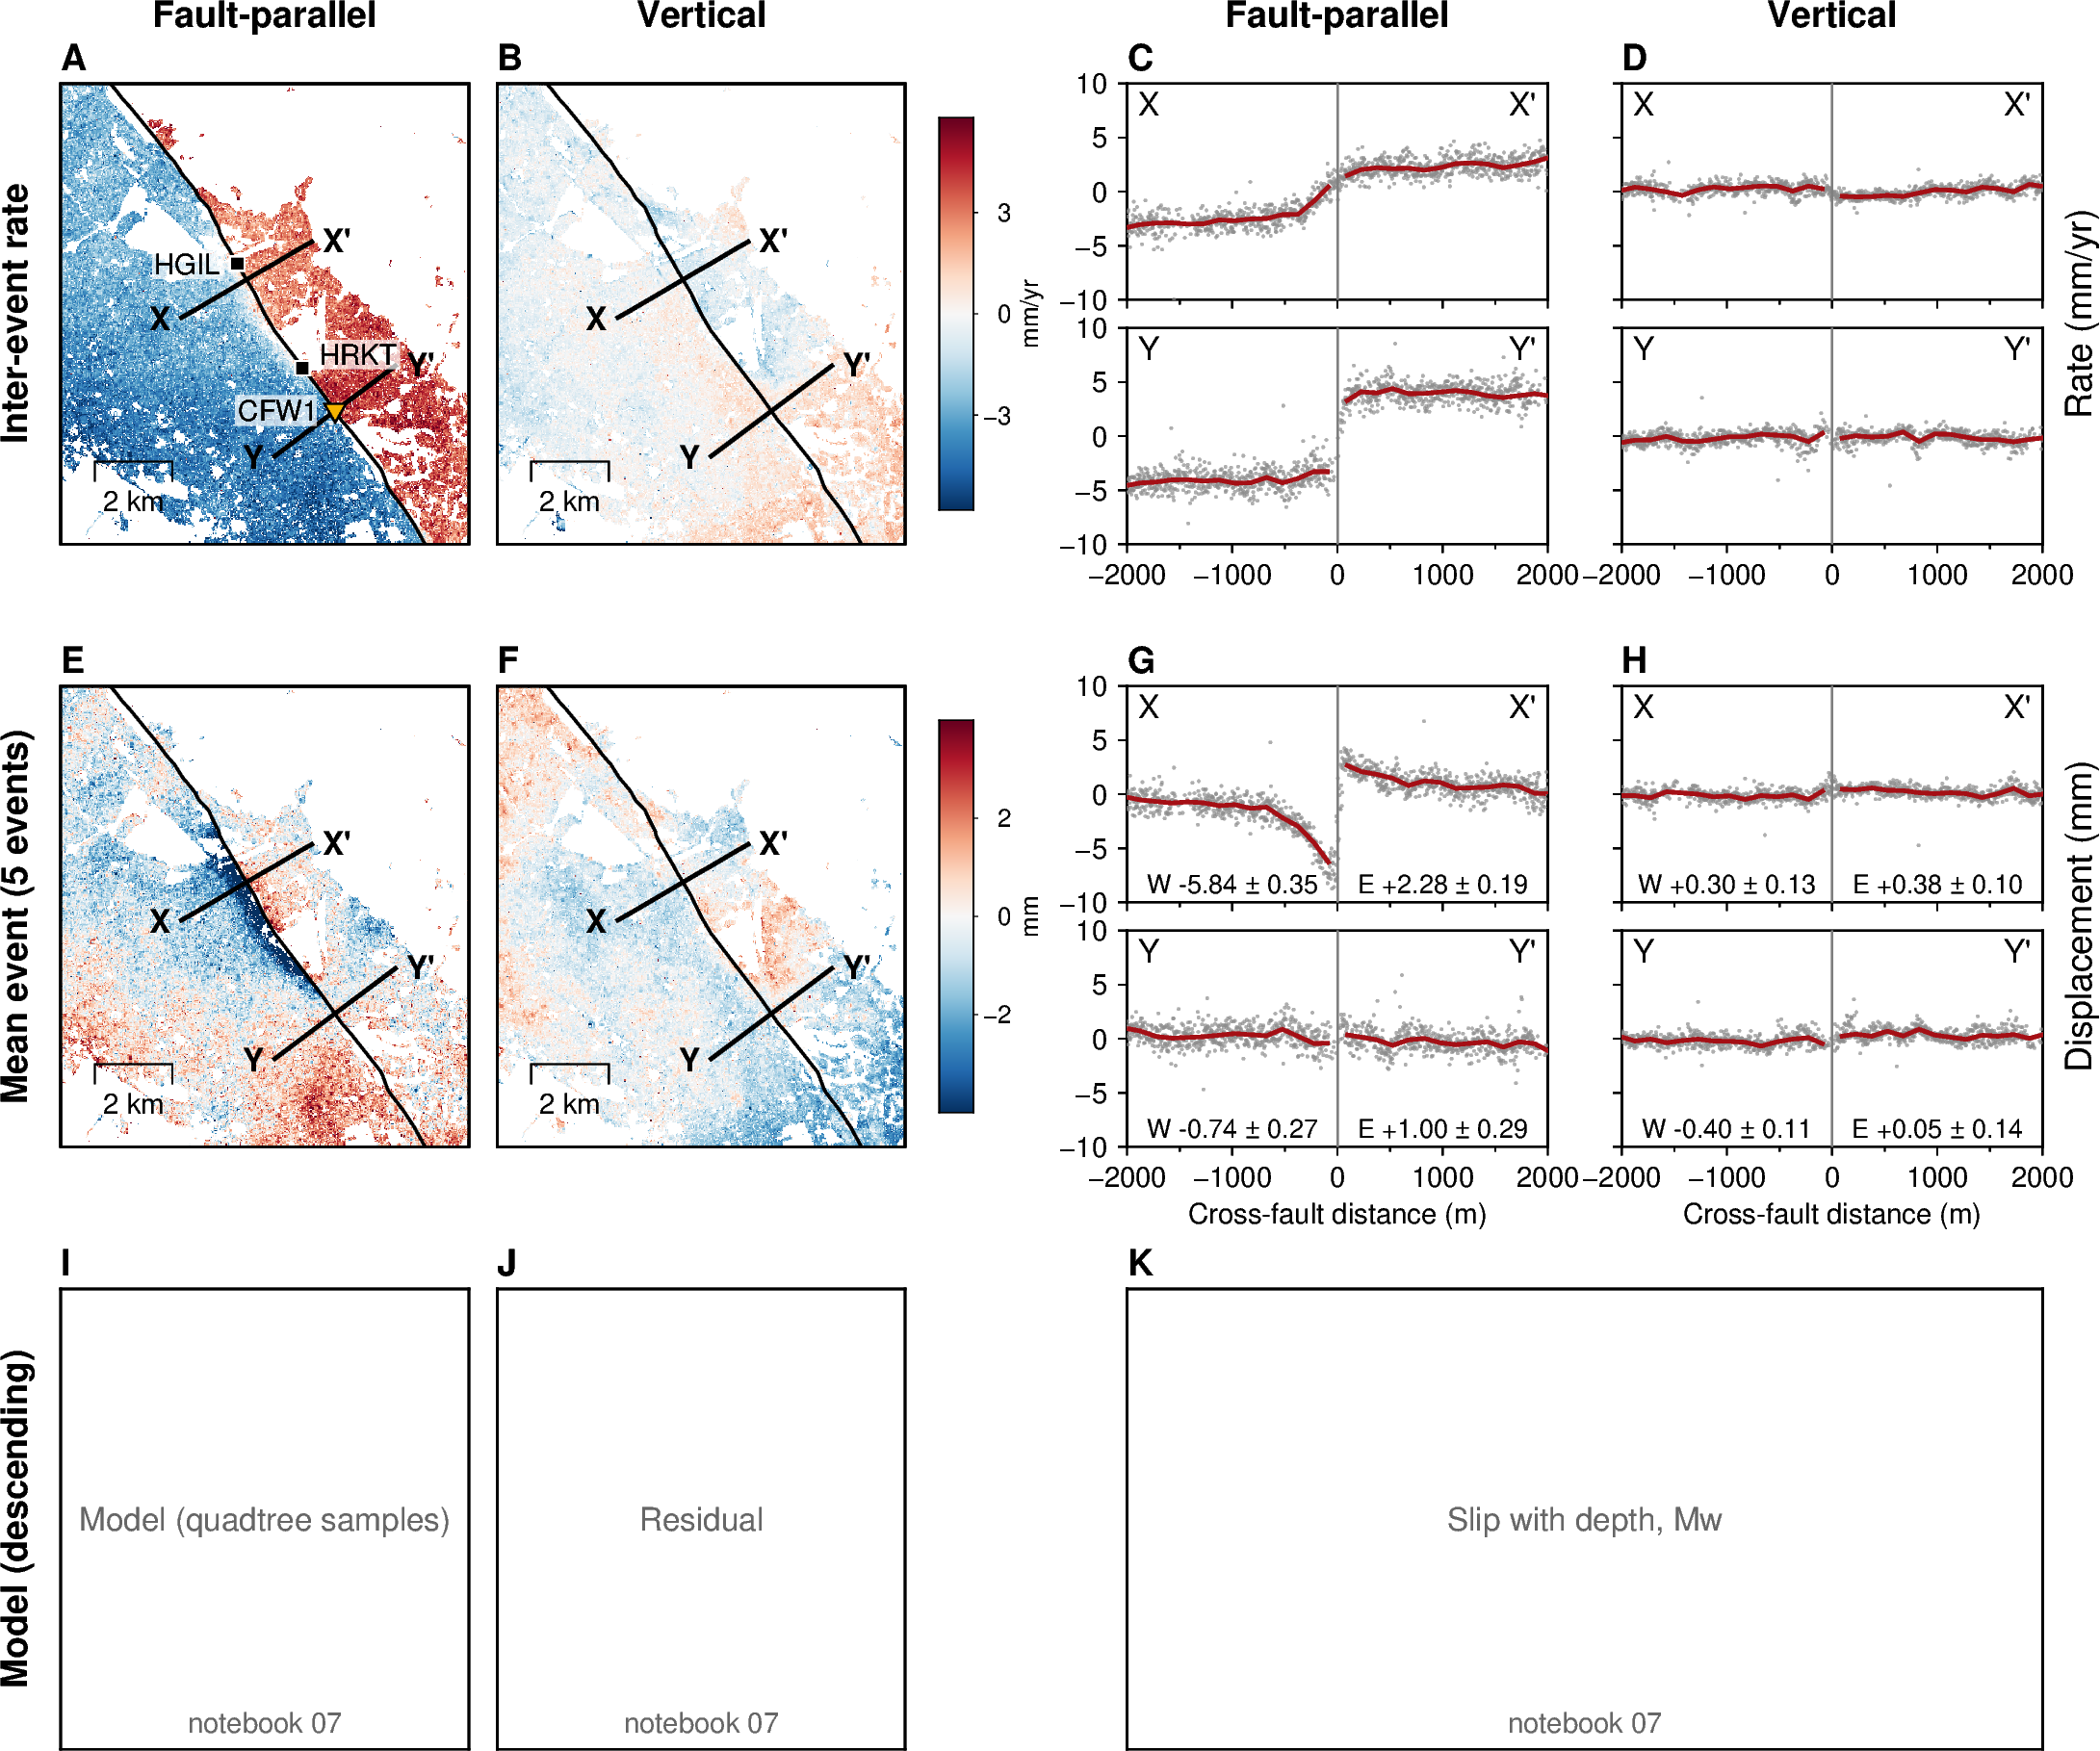

In [18]:
fpup_rate = {"fault-parallel": fp_rate, "vertical": up_rate}
fpup_evt = {"fault-parallel": fp_evt, "vertical": up_evt}
ok_fpup = common_ok & np.all([np.isfinite(f[c]) for f in (fpup_rate, fpup_evt) for c in fpup_rate], axis=0)
fpup_rate = {c: np.where(ok_fpup, m_, np.nan) for c, m_ in fpup_rate.items()}
fpup_evt = {c: np.where(ok_fpup, m_, np.nan) for c, m_ in fpup_evt.items()}
fpup_profiles = {c: {n_: zeroed_profiles(fpup_rate[c], fpup_evt[c], ll) for n_, ll in profile_pts.items()} for c in fpup_rate}
for c in fpup_profiles:
    for n_, p in fpup_profiles[c].items():
        p["blocks"] = block_amplitudes(p["de"], p["ve"])
        print(f"[{c}] {n_}-{n_}': rate step {p['rate_step']:+.2f} mm/yr, event step {p['event_step']:+.2f} mm; "
              f"per block W {p['blocks']['W']['amp']:+.2f}, E {p['blocks']['E']['amp']:+.2f} mm")
draw_fig2(fpup_evt, fpup_profiles, f"Mean event ({n_mean} events)", os.path.join(fig_dir, f"test_fig2_fp_up_coh{coh_maps}_{n_mean}ev"),
          rate_maps_in=fpup_rate, cols=list(fpup_rate), ylabs=("Rate (mm/yr)", "Displacement (mm)"), lims={"rate": 10.0, "event": 10.0})

## Supplement: the fault-parallel maps and profiles

The decomposed field (MintPy `asc_desc2horz_vert`, both tracks) that Fig 2
showed until 2026-09-23: X-X' and Y-Y' through the inter-event rate (top pair)
and the mean event (bottom pair), grey pixels, blue per-side running
median, and the two fault-parallel maps. The numbers quoted in the text
(the near-fault steps) come from these profiles.

psconvert [WARNING]: The -N+g or -N+p options do not support the -!


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


Saved the fault-parallel maps and profiles (supplement) to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-28/figS_fp_maps_coh0.9_5ev.png


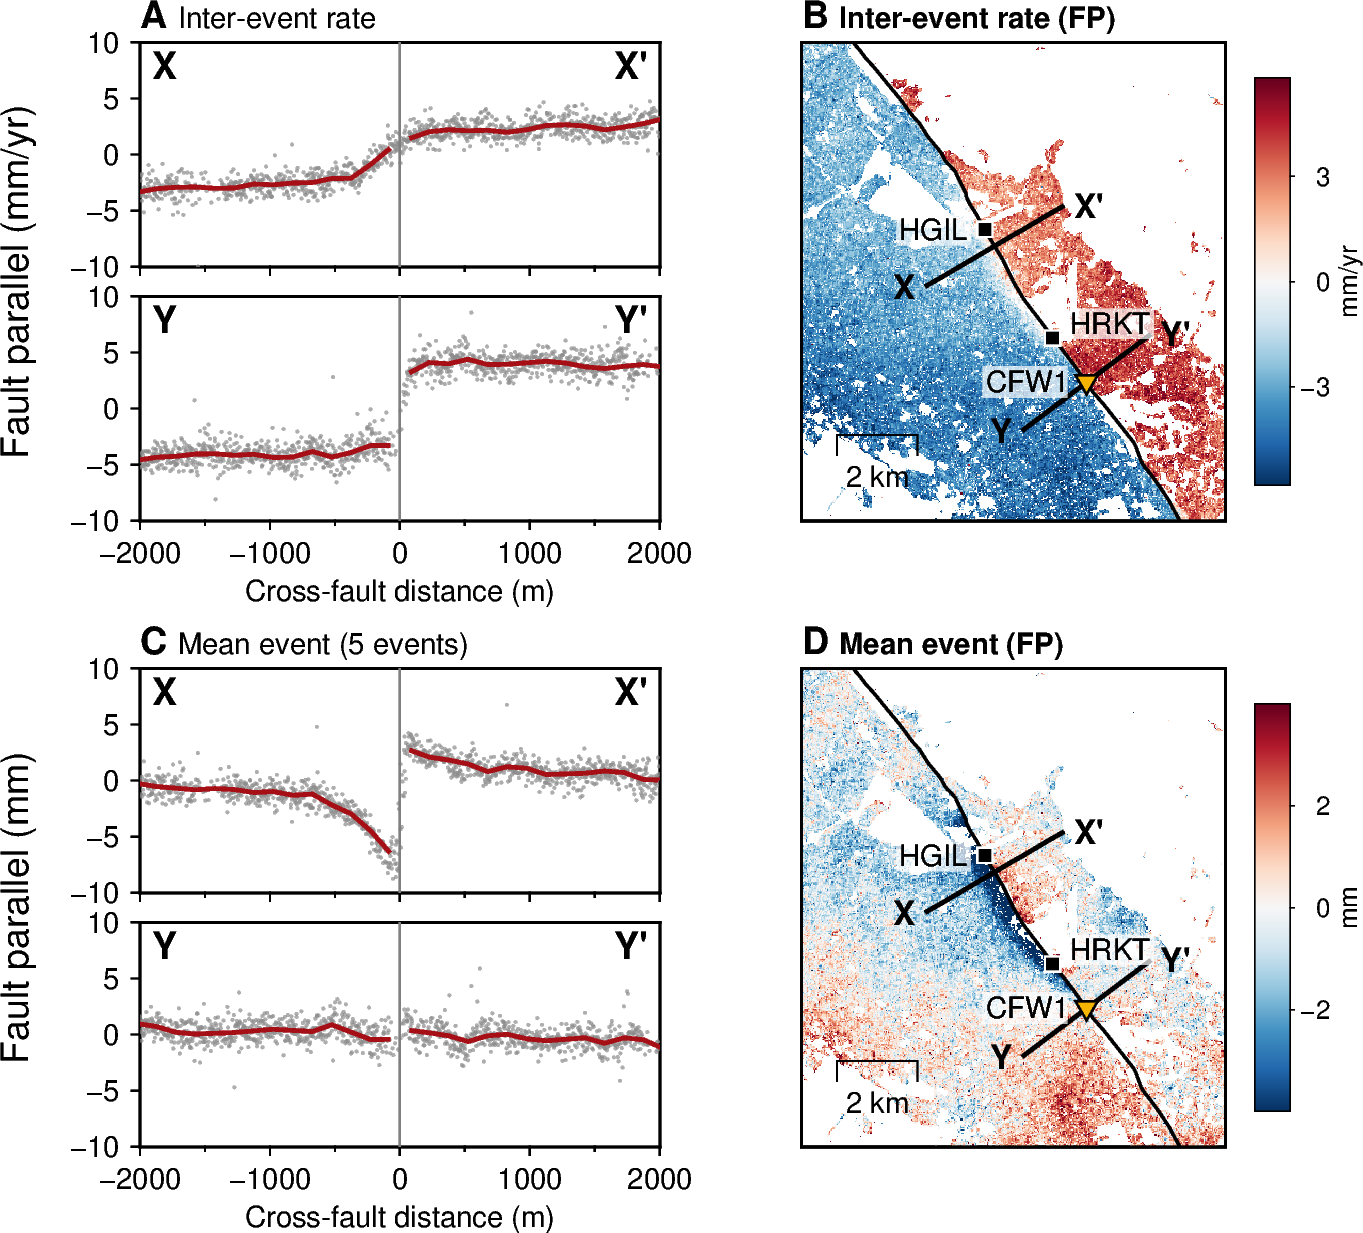

In [19]:
Wp_s, gap_x = 4.4, 1.2                # the supplement keeps its own panel width
names = list(profiles)

fig = pygmt.Figure()                  # the helpers draw into the module-level figure
pygmt.config(FONT="8p,Helvetica", FONT_ANNOT_PRIMARY="7p,Helvetica", FONT_LABEL="7p,Helvetica", MAP_FRAME_TYPE="plain",
             MAP_FRAME_PEN="0.6p", MAP_TICK_LENGTH_PRIMARY="2p", MAP_LABEL_OFFSET="4p", MAP_ANNOT_OFFSET="3p", FORMAT_GEO_MAP="ddd.xx")


def profile_pair(ylab, lim, label, vkey, dkey):
    """Two stacked panels (X above Y) for one field, drawn from the current origin
    (the top panel's bottom-left). Leaves the origin at the LOWER panel."""
    for j, n_ in enumerate(names):
        p = profiles[n_]
        d, v = p[dkey], p[vkey]                                  # zeroed above: the rate at the fault, the event on its far field
        if j > 0:
            fig.shift_origin(yshift=f"-{Hp + gap_pair}c")
        xfr = "xa1000f500+lCross-fault distance (m)" if j == 1 else "xa1000f500"
        fig.basemap(region=[-cross_m, cross_m, -lim, lim], projection=f"X{Wp_s}c/{Hp}c", frame=["WSrt" if j == 1 else "Wsrt", xfr, f"ya{lim / 2:g}"])
        fig.plot(x=d, y=v, style="c0.03c", fill=grey, transparency=30)      # the data
        for xm, vm in running_median(d, v):                                  # the per-side running median
            fig.plot(x=xm, y=vm, pen="1.0p," + median_col)
        fig.plot(x=[0, 0], y=[-lim, lim], pen="0.5p,gray50")
        fig.text(position="TL", text=n_, font="9p,Helvetica-Bold", offset="0.1c/-0.08c")
        fig.text(position="TR", text=n_ + "'", font="9p,Helvetica-Bold", offset="-0.1c/-0.08c")
        if j == 0:
            fig.text(x=-cross_m, y=lim, text=label, justify="BL", offset="0c/0.12c", font="9p,Helvetica", no_clip=True)
    # one y label for the pair, centred on the pair (drawn from the lower panel)
    fig.text(position="ML", text=ylab, angle=90, justify="BC", offset=f"-0.95c/{0.5 * (Hp + gap_pair)}c", font="9p,Helvetica", no_clip=True)


def map_panel(grid, cpt, lim, label, cb_label):
    """A map with its own colour bar."""
    map_base(grid, cpt, label)
    colour_bar(cpt, lim, cb_label, Wm + 0.25)


g_rate, lim_rate = to_grid(fp_rate, True)
g_evt, lim_evt = to_grid(fp_evt, False)
cpt_rate = utils.write_cpt(os.path.join(cpt_dir, "rate.cpt"), "RdBu_r", -lim_rate, lim_rate)
cpt_evt = utils.write_cpt(os.path.join(cpt_dir, "event.cpt"), "RdBu_r", -lim_evt, lim_evt)
# top row: A the inter-event profiles, B the inter-event map (the map is Hpair tall, so its bottom is the pair's bottom)
profile_pair("Fault parallel (mm/yr)", 10.0, "@%Helvetica-Bold%A@%% @:7p:Inter-event rate@::", "v", "d")
fig.shift_origin(xshift=f"{Wp_s + gap_x}c")
map_panel(g_rate, cpt_rate, lim_rate, "@%Helvetica-Bold%B@%% @:7p:Inter-event rate (FP)@::", "mm/yr")
# bottom row: C the mean-event profiles, D the mean-event map
fig.shift_origin(xshift=f"-{Wp_s + gap_x}c", yshift=f"-{gap_row + Hp}c")
profile_pair("Fault parallel (mm)", 10.0, f"@%Helvetica-Bold%C@%% @:7p:Mean event ({n_mean} events)@::", "ve", "de")
fig.shift_origin(xshift=f"{Wp_s + gap_x}c")
map_panel(g_evt, cpt_evt, lim_evt, "@%Helvetica-Bold%D@%% @:7p:Mean event (FP)@::", "mm")

f_figs = os.path.join(fig_dir, f"figS_fp_maps_coh{coh_maps}_{n_mean}ev")
fig.savefig(f_figs + ".png", dpi=300, transparent=False, crop="+gwhite", anti_alias=True, show=False)
fig.savefig(f_figs + ".pdf", transparent=False, crop="+gwhite", anti_alias=True, show=False)
print("Saved the fault-parallel maps and profiles (supplement) to:", f_figs + ".png")
fig.show()

## Supplement: the step maps, every event and track

Rows ascending / descending; columns the five events (burst-fixed), the mean
of the kept events, and the per-pixel scatter across them. LOS mm, positive
toward the satellite, so the two rows have opposite colours across the fault.

In [20]:
clim = 4.0
n_ev = len(onsets)
fig, axes = plt.subplots(2, n_ev + 2, figsize=(2.1 * (n_ev + 2), 5.0), sharex=True, sharey=True)
for r_, orbit in enumerate(event_maps):
    panels = [(event_maps[orbit]["ev"][i], f"{oy:.2f}" + (" (excl.)" if any(abs(oy - x) < 0.02 for x in exclude_events) else ""), "RdBu_r", (-clim, clim))
              for i, (_, _, oy) in enumerate(fits[orbit]["steps"])]
    panels += [(mean_event[orbit]["mean"], f"mean of {mean_event[orbit]['n']}", "RdBu_r", (-clim, clim)),
               (mean_event[orbit]["scatter"], "scatter (sd)", "viridis", (0, clim))]
    for c_, (m_, ttl, cmap, cl) in enumerate(panels):
        ax = axes[r_, c_]
        im = ax.pcolormesh(lon_g, lat_g, m_, cmap=cmap, vmin=cl[0], vmax=cl[1], shading="nearest", rasterized=True)
        ax.plot(prof.ft_lon, prof.ft_lat, "k-", lw=0.5)
        ax.set_xlim(box_lonlat[0], box_lonlat[2]); ax.set_ylim(box_lonlat[1], box_lonlat[3]); ax.set_aspect(1 / np.cos(np.deg2rad(37.55)))
        ax.set_title(f"{orbit[:3]} {ttl}", fontsize=8, loc="left")
        ax.tick_params(labelsize=6)
        if r_ == 1 and c_ in (0, n_ev + 1):
            fig.colorbar(im, ax=axes[:, c_] if c_ else axes[:, :n_ev + 1], shrink=0.5, orientation="horizontal", pad=0.06, label="LOS mm" if c_ == 0 else "mm")
fig.suptitle(f"Per-pixel step maps, coherence {coh_timeseries}, box median removed, descending burst offsets removed", fontsize=9)
f_grid = os.path.join(fig_dir, f"figS_event_step_maps_coh{coh_maps}.png")
fig.savefig(f_grid, dpi=300, bbox_inches="tight"); print("Saved figure to:", f_grid); plt.show()

Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-28/figS_event_step_maps_coh0.9.png


/var/folders/bz/z50q20pn1fsbtbkbs0bcrqf00000gp/T/ipykernel_87038/1924541052.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig(f_grid, dpi=300, bbox_inches="tight"); print("Saved figure to:", f_grid); plt.show()


## REGISTER

In [21]:
L_ = [f"06 EVENT FIELD GEOMETRY  (coherence {coh_timeseries}, box {box_lonlat}, {nr} x {nc} px)",
      f"local strike {strike:.2f} deg; LOS.strike asc {L['ascending'] @ s_hat:+.3f} desc {L['descending'] @ s_hat:+.3f}, geometric asc/desc ratio {geom_ratio:+.2f}",
      f"per-event near-fault LOS steps (east - west, {xfault_step_m[0]:.0f}-{xfault_step_m[1]:.0f} m, stacked band):"]
for _, r_ in steps_df.iterrows():
    L_.append(f"   {r_.onset_yr:.2f}: asc {r_.ascending_step_mm:+.2f} mm, desc {r_.descending_step_mm:+.2f} mm, ratio {r_.ratio_asc_desc:+.2f}")
L_.append("symmetric / antisymmetric parts at 1 km (mm):")
for oy, r_ in sym_wide.iterrows():
    L_.append(f"   {oy:.2f}: asc A {r_[('antisym_1km_mm', 'ascending')]:+.2f} S {r_[('sym_1km_mm', 'ascending')]:+.2f} | "
              f"desc A {r_[('antisym_1km_mm', 'descending')]:+.2f} S {r_[('sym_1km_mm', 'descending')]:+.2f}")
L_.append(f"excluded from the mean: {exclude_events}; mean event = {mean_event['ascending']['n']} events")
for _, r_ in burst_df.iterrows():
    L_.append(f"   burst fix {r_.track} lat {r_.line_lat:.3f} event {r_.onset_yr:.2f}: {r_.offset_mm:+.2f} mm")
L_.append(f"FP inter-event step (stacked band) {block_step(fp_rate):+.2f} mm/yr, Up {block_step(up_rate):+.2f}; FP mean event {block_step(fp_evt):+.2f} mm, Up {block_step(up_evt):+.2f}")
L_.append(f"profiles, near-fault steps east - west ({xfault_step_m[0]:.0f}-{xfault_step_m[1]:.0f} m), +/-{cross_m / 1e3:g} km, swath +/-{swath_m:.0f} m:")
for n_ in names:
    L_.append(f"   {n_}-{n_}' ({profiles[n_]['lonlat'][1]:.4f} N, local strike {profiles[n_]['strike']:.1f} deg): inter-event {profiles[n_]['rate_step']:+.2f} mm/yr, event {profiles[n_]['event_step']:+.2f} mm (n {profiles[n_]['d'].size})")
L_.append("LOS profiles per track (Fig 2), near-fault steps east - west, LOS positive toward the satellite:")
for o in tracks:
    for n_ in names:
        b_ = los_profiles[o][n_]["blocks"]
        L_.append(f"   {o[:3]} {n_}-{n_}': inter-event {los_profiles[o][n_]['rate_step']:+.2f} mm/yr, event {los_profiles[o][n_]['event_step']:+.2f} mm; "
                  f"event per block (near {xfault_step_m[0]:.0f}-{xfault_step_m[1]:.0f} m over far {far_m[0]:.0f}-{far_m[1]:.0f} m) "
                  f"W {b_['W']['amp']:+.2f} +/- {b_['W']['se']:.2f}, E {b_['E']['amp']:+.2f} +/- {b_['E']['se']:.2f} mm")
L_.append(f"X-X' event asc/desc LOS step ratio {xx_ratio:+.2f} (geometric {geom_ratio:+.2f})")
L_.append(f"ascending deficit (mean steps asc {m_asc:+.2f}, desc {m_desc:+.2f} mm): strike-slip only {fp_only:.2f} mm; "
          f"with vertical FP {asym['up'][0]:.2f} mm + east side up {asym['up'][1]:+.2f} mm; "
          f"with fault-normal FP {asym['normal'][0]:.2f} mm + east block opening {asym['normal'][1]:+.2f} mm")
print("\n".join(L_))
sidecar = REG.sidecar("06_event_field", L_)

REG.register("06_strike_local_deg", strike, "deg", 2, where="M4", cell="strike", sidecar=sidecar)
REG.register("06_asc_desc_geom_ratio", geom_ratio, "", 2, where="M4", cell="los-steps", sidecar=sidecar)
REG.register("06_n_events_mean", mean_event["ascending"]["n"], "count", 0, where="M4", cell="mean-event", sidecar=sidecar)
for _, r_ in steps_df.iterrows():
    tag = f"{int(r_.onset_yr)}"
    REG.register(f"06_los_step_asc_{tag}_mm", r_.ascending_step_mm, "mm", 2, where="S", cell="los-steps", sidecar=sidecar)
    REG.register(f"06_los_step_desc_{tag}_mm", r_.descending_step_mm, "mm", 2, where="S", cell="los-steps", sidecar=sidecar)
    REG.register(f"06_step_ratio_{tag}", r_.ratio_asc_desc, "", 2, where="S", cell="los-steps", sidecar=sidecar)
for oy, r_ in sym_wide.iterrows():
    tag = f"{int(oy)}"
    REG.register(f"06_sym_asc_{tag}_mm", r_[("sym_1km_mm", "ascending")], "mm", 2, where="S", cell="symmetry", sidecar=sidecar)
    REG.register(f"06_sym_desc_{tag}_mm", r_[("sym_1km_mm", "descending")], "mm", 2, where="S", cell="symmetry", sidecar=sidecar)
for _, r_ in burst_df.iterrows():
    REG.register(f"06_burst_{r_.line_lat:.3f}_{int(r_.onset_yr)}_mm", r_.offset_mm, "mm", 2, where="S", cell="burst-fix", sidecar=sidecar)
REG.register("06_fp_rate_step_mm_yr", block_step(fp_rate), "mm/yr", 2, where="P6", cell="decompose", sidecar=sidecar)
REG.register("06_up_rate_step_mm_yr", block_step(up_rate), "mm/yr", 2, where="S", cell="decompose", sidecar=sidecar)
REG.register("06_fp_event_step_mm", block_step(fp_evt), "mm", 2, where="P6", cell="decompose", sidecar=sidecar)
REG.register("06_up_event_step_mm", block_step(up_evt), "mm", 2, where="S", cell="decompose", sidecar=sidecar)
for n_ in names:
    REG.register(f"06_{n_}{n_}_strike_local_deg", profiles[n_]["strike"], "deg", 1, where="Fig2", cell="profiles", sidecar=sidecar)
    REG.register(f"06_{n_}{n_}_rate_step_mm_yr", profiles[n_]["rate_step"], "mm/yr", 2, where="P6", cell="profiles", sidecar=sidecar)
    REG.register(f"06_{n_}{n_}_event_step_mm", profiles[n_]["event_step"], "mm", 2, where="P6", cell="profiles", sidecar=sidecar)
for o in tracks:
    for n_ in names:
        REG.register(f"06_{n_}{n_}_rate_step_{o[:3]}_mm_yr", los_profiles[o][n_]["rate_step"], "mm/yr", 2, where="Fig2", cell="los-profiles", sidecar=sidecar)
        REG.register(f"06_{n_}{n_}_event_step_{o[:3]}_mm", los_profiles[o][n_]["event_step"], "mm", 2, where="Fig2", cell="los-profiles", sidecar=sidecar)
        for blk in ("W", "E"):
            REG.register(f"06_{n_}{n_}_event_{blk}_{o[:3]}_mm", los_profiles[o][n_]["blocks"][blk]["amp"], "mm", 2, where="Fig2", cell="los-profiles", sidecar=sidecar)
            REG.register(f"06_{n_}{n_}_event_{blk}_{o[:3]}_se_mm", los_profiles[o][n_]["blocks"][blk]["se"], "mm", 2, where="Fig2", cell="los-profiles", sidecar=sidecar)
REG.register("06_XX_event_ratio_asc_desc", xx_ratio, "", 2, where="S2", cell="los-profiles", sidecar=sidecar)
REG.register("06_asym_fp_only_mm", fp_only, "mm", 2, where="S2", cell="asymmetry", sidecar=sidecar)
REG.register("06_asym_fp_with_up_mm", asym["up"][0], "mm", 2, where="S2", cell="asymmetry", sidecar=sidecar)
REG.register("06_asym_east_up_mm", asym["up"][1], "mm", 2, where="S2", cell="asymmetry", sidecar=sidecar)
REG.register("06_asym_fp_with_normal_mm", asym["normal"][0], "mm", 2, where="S2", cell="asymmetry", sidecar=sidecar)
REG.register("06_asym_east_opening_mm", asym["normal"][1], "mm", 2, where="S2", cell="asymmetry", sidecar=sidecar)
for orbit in mean_event:
    REG.register(f"06_n_px_csi_{orbit[:3]}", int(np.isfinite(mean_event[orbit]["mean"]).sum()), "count", 0, where="M4", cell="mean-event", sidecar=sidecar)
REG.render()
print("registered; see", common_paths["registry_txt"])

06 EVENT FIELD GEOMETRY  (coherence 0.7, box (-122.1, 37.46, -121.84, 37.65), 712 x 774 px)
local strike 146.44 deg; LOS.strike asc -0.263 desc +0.468, geometric asc/desc ratio -0.56
per-event near-fault LOS steps (east - west, 30-150 m, stacked band):
   2017.10: asc -2.48 mm, desc +4.10 mm, ratio -0.60
   2019.19: asc -1.43 mm, desc +5.21 mm, ratio -0.28
   2021.11: asc -2.61 mm, desc +4.13 mm, ratio -0.63
   2023.08: asc -1.23 mm, desc +5.73 mm, ratio -0.21
   2024.98: asc -1.16 mm, desc +3.52 mm, ratio -0.33
symmetric / antisymmetric parts at 1 km (mm):
   2017.10: asc A -0.36 S -0.17 | desc A +0.64 S +0.51
   2019.19: asc A -0.03 S -1.22 | desc A +1.39 S +0.54
   2021.11: asc A -0.10 S -0.34 | desc A +0.63 S +0.97
   2023.08: asc A +0.50 S -1.96 | desc A +0.57 S +0.37
   2024.98: asc A +0.06 S -0.67 | desc A +0.76 S +0.53
excluded from the mean: []; mean event = 5 events
   burst fix descending lat 37.536 event 2017.10: -0.42 mm
   burst fix descending lat 37.536 event 2019.19: -0

  registered 06_los_step_asc_2017_mm = -2.48 mm  -> S
  registered 06_los_step_desc_2017_mm = 4.10 mm  -> S
  registered 06_step_ratio_2017 = -0.60   -> S
  registered 06_los_step_asc_2019_mm = -1.43 mm  -> S
  registered 06_los_step_desc_2019_mm = 5.21 mm  -> S
  registered 06_step_ratio_2019 = -0.28   -> S


  registered 06_los_step_asc_2021_mm = -2.61 mm  -> S
  registered 06_los_step_desc_2021_mm = 4.13 mm  -> S
  registered 06_step_ratio_2021 = -0.63   -> S
  registered 06_los_step_asc_2023_mm = -1.23 mm  -> S
  registered 06_los_step_desc_2023_mm = 5.73 mm  -> S
  registered 06_step_ratio_2023 = -0.21   -> S


  registered 06_los_step_asc_2024_mm = -1.16 mm  -> S
  registered 06_los_step_desc_2024_mm = 3.52 mm  -> S
  registered 06_step_ratio_2024 = -0.33   -> S
  registered 06_sym_asc_2017_mm = -0.17 mm  -> S
  registered 06_sym_desc_2017_mm = 0.51 mm  -> S
  registered 06_sym_asc_2019_mm = -1.22 mm  -> S


  registered 06_sym_desc_2019_mm = 0.54 mm  -> S
  registered 06_sym_asc_2021_mm = -0.34 mm  -> S
  registered 06_sym_desc_2021_mm = 0.97 mm  -> S
  registered 06_sym_asc_2023_mm = -1.96 mm  -> S
  registered 06_sym_desc_2023_mm = 0.37 mm  -> S
  registered 06_sym_asc_2024_mm = -0.67 mm  -> S


  registered 06_sym_desc_2024_mm = 0.53 mm  -> S
  registered 06_burst_37.536_2017_mm = -0.42 mm  -> S
  registered 06_burst_37.536_2019_mm = -0.23 mm  -> S
  registered 06_burst_37.536_2021_mm = -0.12 mm  -> S
  registered 06_burst_37.536_2023_mm = -0.08 mm  -> S
  registered 06_burst_37.536_2024_mm = -0.95 mm  -> S


... (4 outputs left out)

  registered 06_YY_event_E_asc_mm = -0.20 mm  -> Fig2
  registered 06_YY_event_E_asc_se_mm = 0.22 mm  -> Fig2
  registered 06_XX_rate_step_des_mm_yr = -0.05 mm/yr  -> Fig2
  registered 06_XX_event_step_des_mm = 4.55 mm  -> Fig2
  registered 06_XX_event_W_des_mm = -2.61 mm  -> Fig2
  registered 06_XX_event_W_des_se_mm = 0.15 mm  -> Fig2


  registered 06_XX_event_E_des_mm = 1.26 mm  -> Fig2
  registered 06_XX_event_E_des_se_mm = 0.09 mm  -> Fig2
  registered 06_YY_rate_step_des_mm_yr = 2.83 mm/yr  -> Fig2
  registered 06_YY_event_step_des_mm = 1.11 mm  -> Fig2
  registered 06_YY_event_W_des_mm = -0.63 mm  -> Fig2
  registered 06_YY_event_W_des_se_mm = 0.16 mm  -> Fig2


  registered 06_YY_event_E_des_mm = 0.57 mm  -> Fig2
  registered 06_YY_event_E_des_se_mm = 0.10 mm  -> Fig2
  registered 06_XX_event_ratio_asc_desc = -0.52   -> S2
  registered 06_asym_fp_only_mm = 8.99 mm  -> S2
  registered 06_asym_fp_with_up_mm = 8.67 mm  -> S2
  registered 06_asym_east_up_mm = 0.66 mm  -> S2


  registered 06_asym_fp_with_normal_mm = 12.25 mm  -> S2
  registered 06_asym_east_opening_mm = -2.40 mm  -> S2
  registered 06_n_px_csi_asc = 165774 count  -> M4
  registered 06_n_px_csi_des = 167555 count  -> M4
Rendered registry to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt
registered; see /Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt
